# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-03-17
> - Modified: 2025-01-03

---

# Experimental Design

> - https://www.10xgenomics.com/cn/datasets/10k-human-pbmcs-3-ht-v3-1-chromium-x-3-1-high

| Sample | Cell/Tissue | Organism | Full name | Gender | Age | Disease status | Library | Source |
| - | - | - | - | - | - | - | - | - |
| Donor | PBMCs | Homo sapiens | Peripheral blood mononuclear cells | Female | 25-30 | Healthy | 10X 3' V3.1 scRNA-seq | AllCells |

> - Chromium Single Cell 3' Reagent Kits (v3.1 Chemistry Dual Index, CG000315 Rev C)
> - Chromium X
>     - input: ~ 16,000 cells
>     - recovered: 11,996 cells
> - Illumina NovaSeq 6000
> - Cell Ranger 6.1.0 with --expect-cells = 10000

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_10k"

In [3]:
scrna <- readRDS(file.path(
    data_dir, "result", "s8_annotation_seurat_V5.rds"))

In [4]:
scrna

An object of class Seurat 
42335 features across 10232 samples within 2 assays 
Active assay: RNA (22302 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, umap, tsne

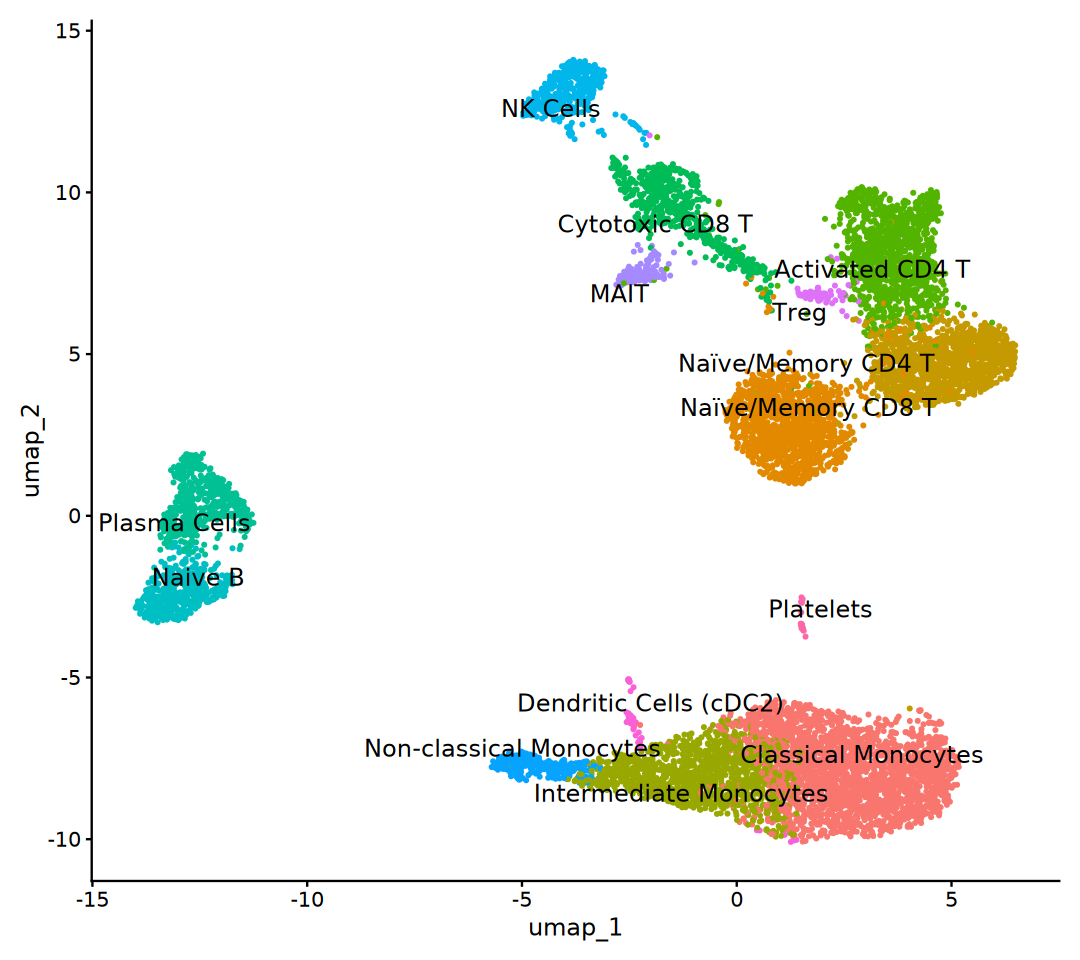

In [5]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(scrna, reduction = "umap", pt.size = 0.5, 
        label = TRUE, repel = TRUE, label.size = 5) + 
    NoLegend()

In [6]:
Idents(scrna) <- scrna$seurat_clusters

# 2. Cluster Biomarkers

In [7]:
sc.markers <- FindAllMarkers(
    scrna, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = TRUE, verbose = FALSE)

In [8]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [9]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13
length(gene),1090,115,77,1659,121,133,235,157,211,1806,161,101,1010,269


In [10]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

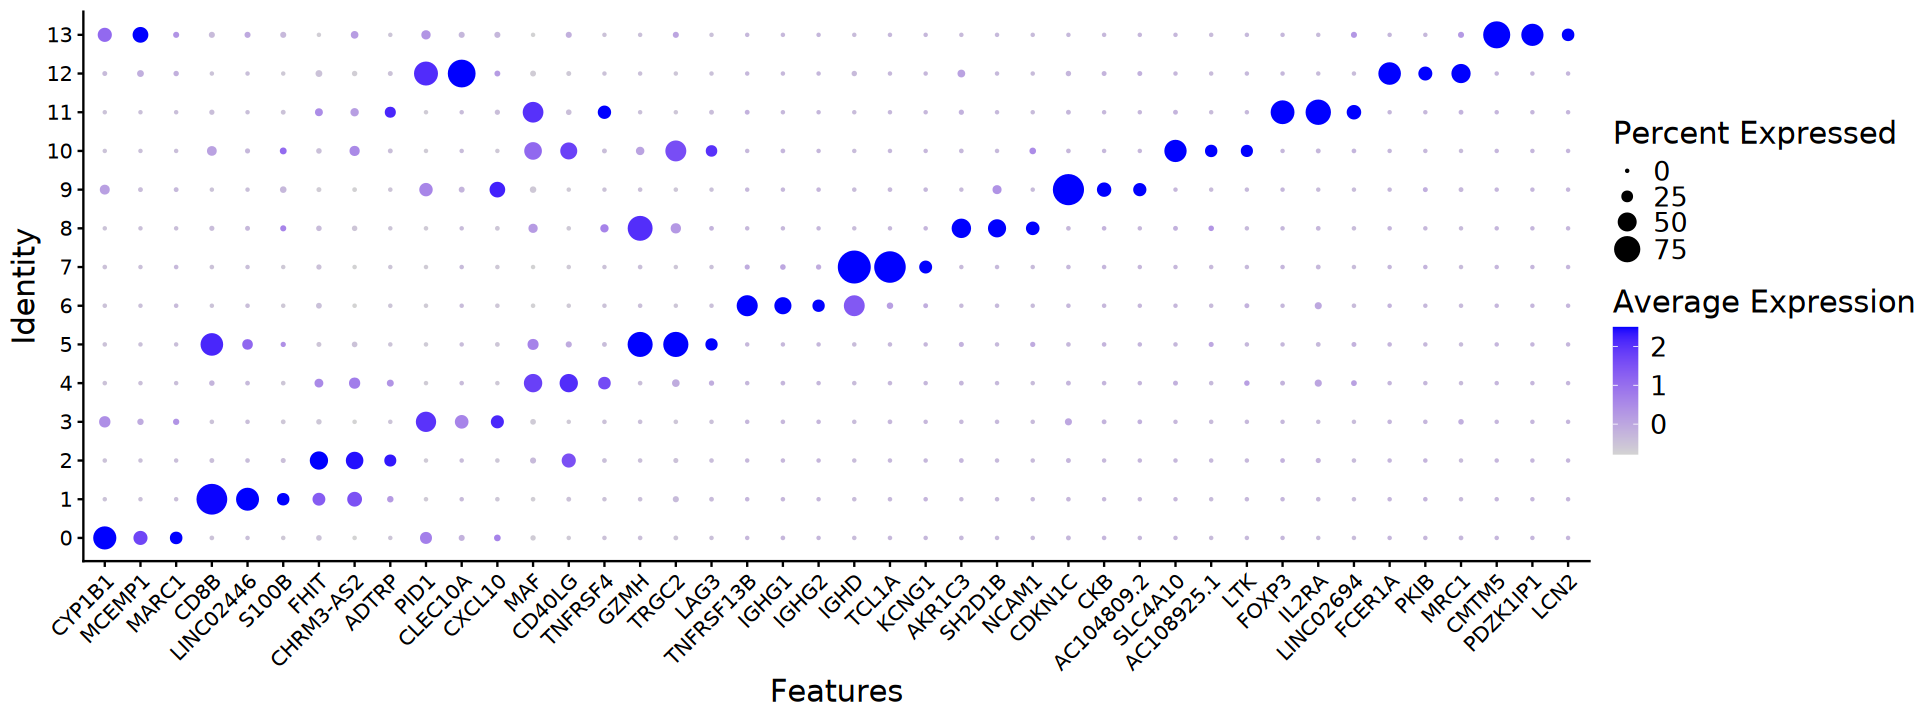

In [11]:
options(repr.plot.width = 16, repr.plot.height = 6)
DotPlot(scrna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

# 3. Cell-type Annotation

In [12]:
# # Convert Seurat V5 to V3
# scDat.seuratV3 <- scDat.integrate
# scDat.seuratV3[["RNA"]] <- as(object = scDat.integrate[["RNA"]], Class = "Assay")
# scDat.seuratV3

## a). Manual

Cell population annotation based on differentially expressed genes in clusters and cell type marker genes.

In [13]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [14]:
gene_list |> cat(sep = "\n")

cluster_0: "S100A12", "S100A8", "CYP1B1", "CES1", "THBS1", "QPCT", "CRISPLD2", "MCEMP1", "CLEC4D", "MARC1"
cluster_1: "CD8B", "CD8A", "KLRK1", "LINC02446", "NELL2", "LRRN3", "S100B", "PASK", "PDE3B", "SCGB3A1"
cluster_2: "CCR7", "LEF1", "FHIT", "TRABD2A", "CHRM3-AS2", "ADTRP", "TRAT1", "CD40LG", "LINC01550", "FBLN5"
cluster_3: "LGALS2", "CPVL", "PEA15", "PID1", "SERPING1", "CLEC10A", "RTN1", "CXCL10", "SRC", "DHRS9"
cluster_4: "AQP3", "GPR183", "INPP4B", "MAF", "CD40LG", "TNFRSF4", "CD28", "TNFRSF25", "GATA3", "ANK3"
cluster_5: "CCL5", "KLRG1", "GZMH", "TRGC2", "LINC01871", "FCRL6", "GZMK", "A2M-AS1", "LAG3", "EOMES"
cluster_6: "TNFRSF13B", "JCHAIN", "LINC01857", "IGHA1", "CPNE5", "IGHG1", "IGHG3", "LINC01781", "PPP1R14A", "IGHG2"
cluster_7: "IGHD", "TCL1A", "FCER2", "FCRL1", "CD72", "TSPAN13", "COL19A1", "CD200", "PCDH9", "KCNG1"
cluster_8: "KLRF1", "GZMB", "SPON2", "CLIC3", "AKR1C3", "SH2D1B", "NMUR1", "NCR1", "NCAM1", "RNF165"
cluster_9: "CDKN1C", "HES4", "FCGR3A", "CTSL", "MS4A4A",

In [15]:
typical_lineage_marker_list <- list(
    "Naive_CD4_T" = c("CCR7", "IL7R", "TCF7", "LTB", "MAL", "TRAC", "SELL"),
    "Activated_CD4_T" = c("IL2RA", "TNFRSF4", "TNFRSF18", "CD69", "HLA-DRA"),
    "Effector_CD4_T" = c("CXCL13", "GZMB", "PRF1", "GNLY", "IFNG"),
	"CD8_T" = c("CD8A", "CD8B", "GZMK", "GZMB", "NKG7", "LST1"),
	"NK" = c("NKG7", "GNLY", "FCGR3A", "KLRD1", "PRF1", "GZMB"),
	"Naive_B" = c("MS4A1", "CD79A", "CD79B", "CD74", "HLA-DRA", "BANK1"),
	"Memory_B" = c("CD27", "TNFRSF13B", "HLA-DQA1", "HLA-DQB1", "AIM2"),
	"Plasmablasts" = c("MZB1", "XBP1", "SDC1", "PRDM1", "IGHG1", "IGHM"),
	"Monocytes" = c("LYZ", "S100A8", "S100A9", "LGALS3", "FCN1"),
	"Dendritic_cells" = c("LILRA4", "CLEC4C", "IRF7", "GZMB"),
	"Platelets" = c("PPBP", "PF4", "NRGN", "RGS18")
)

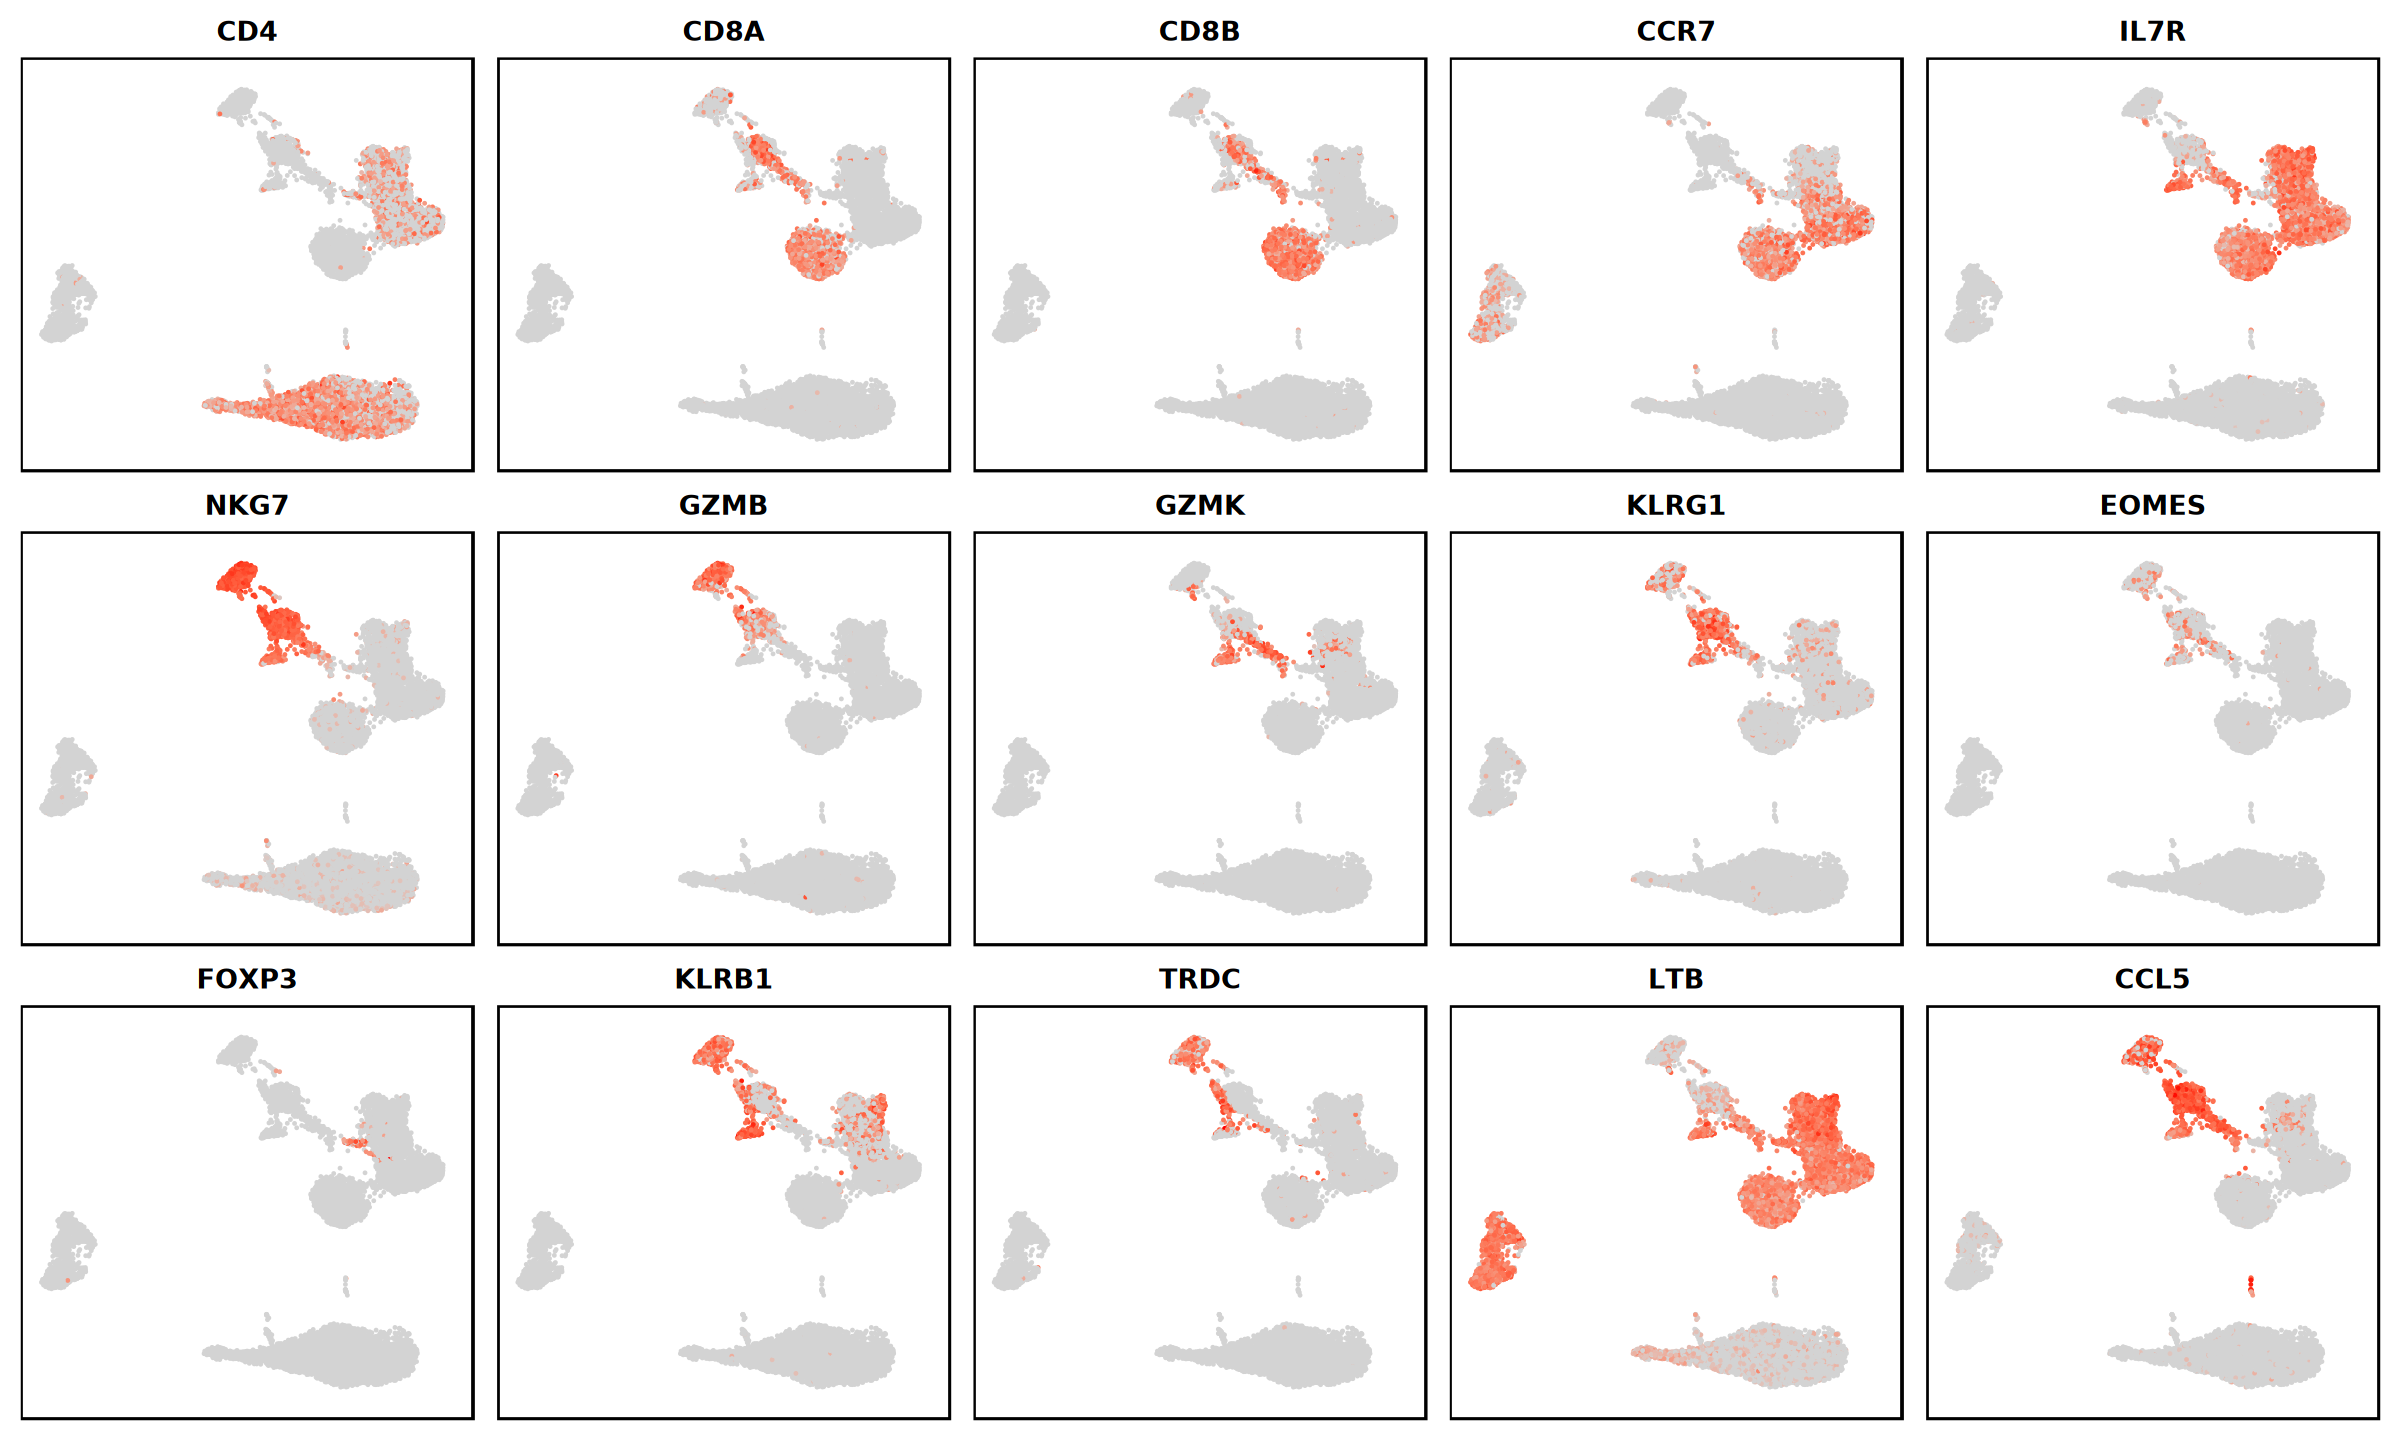

In [16]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

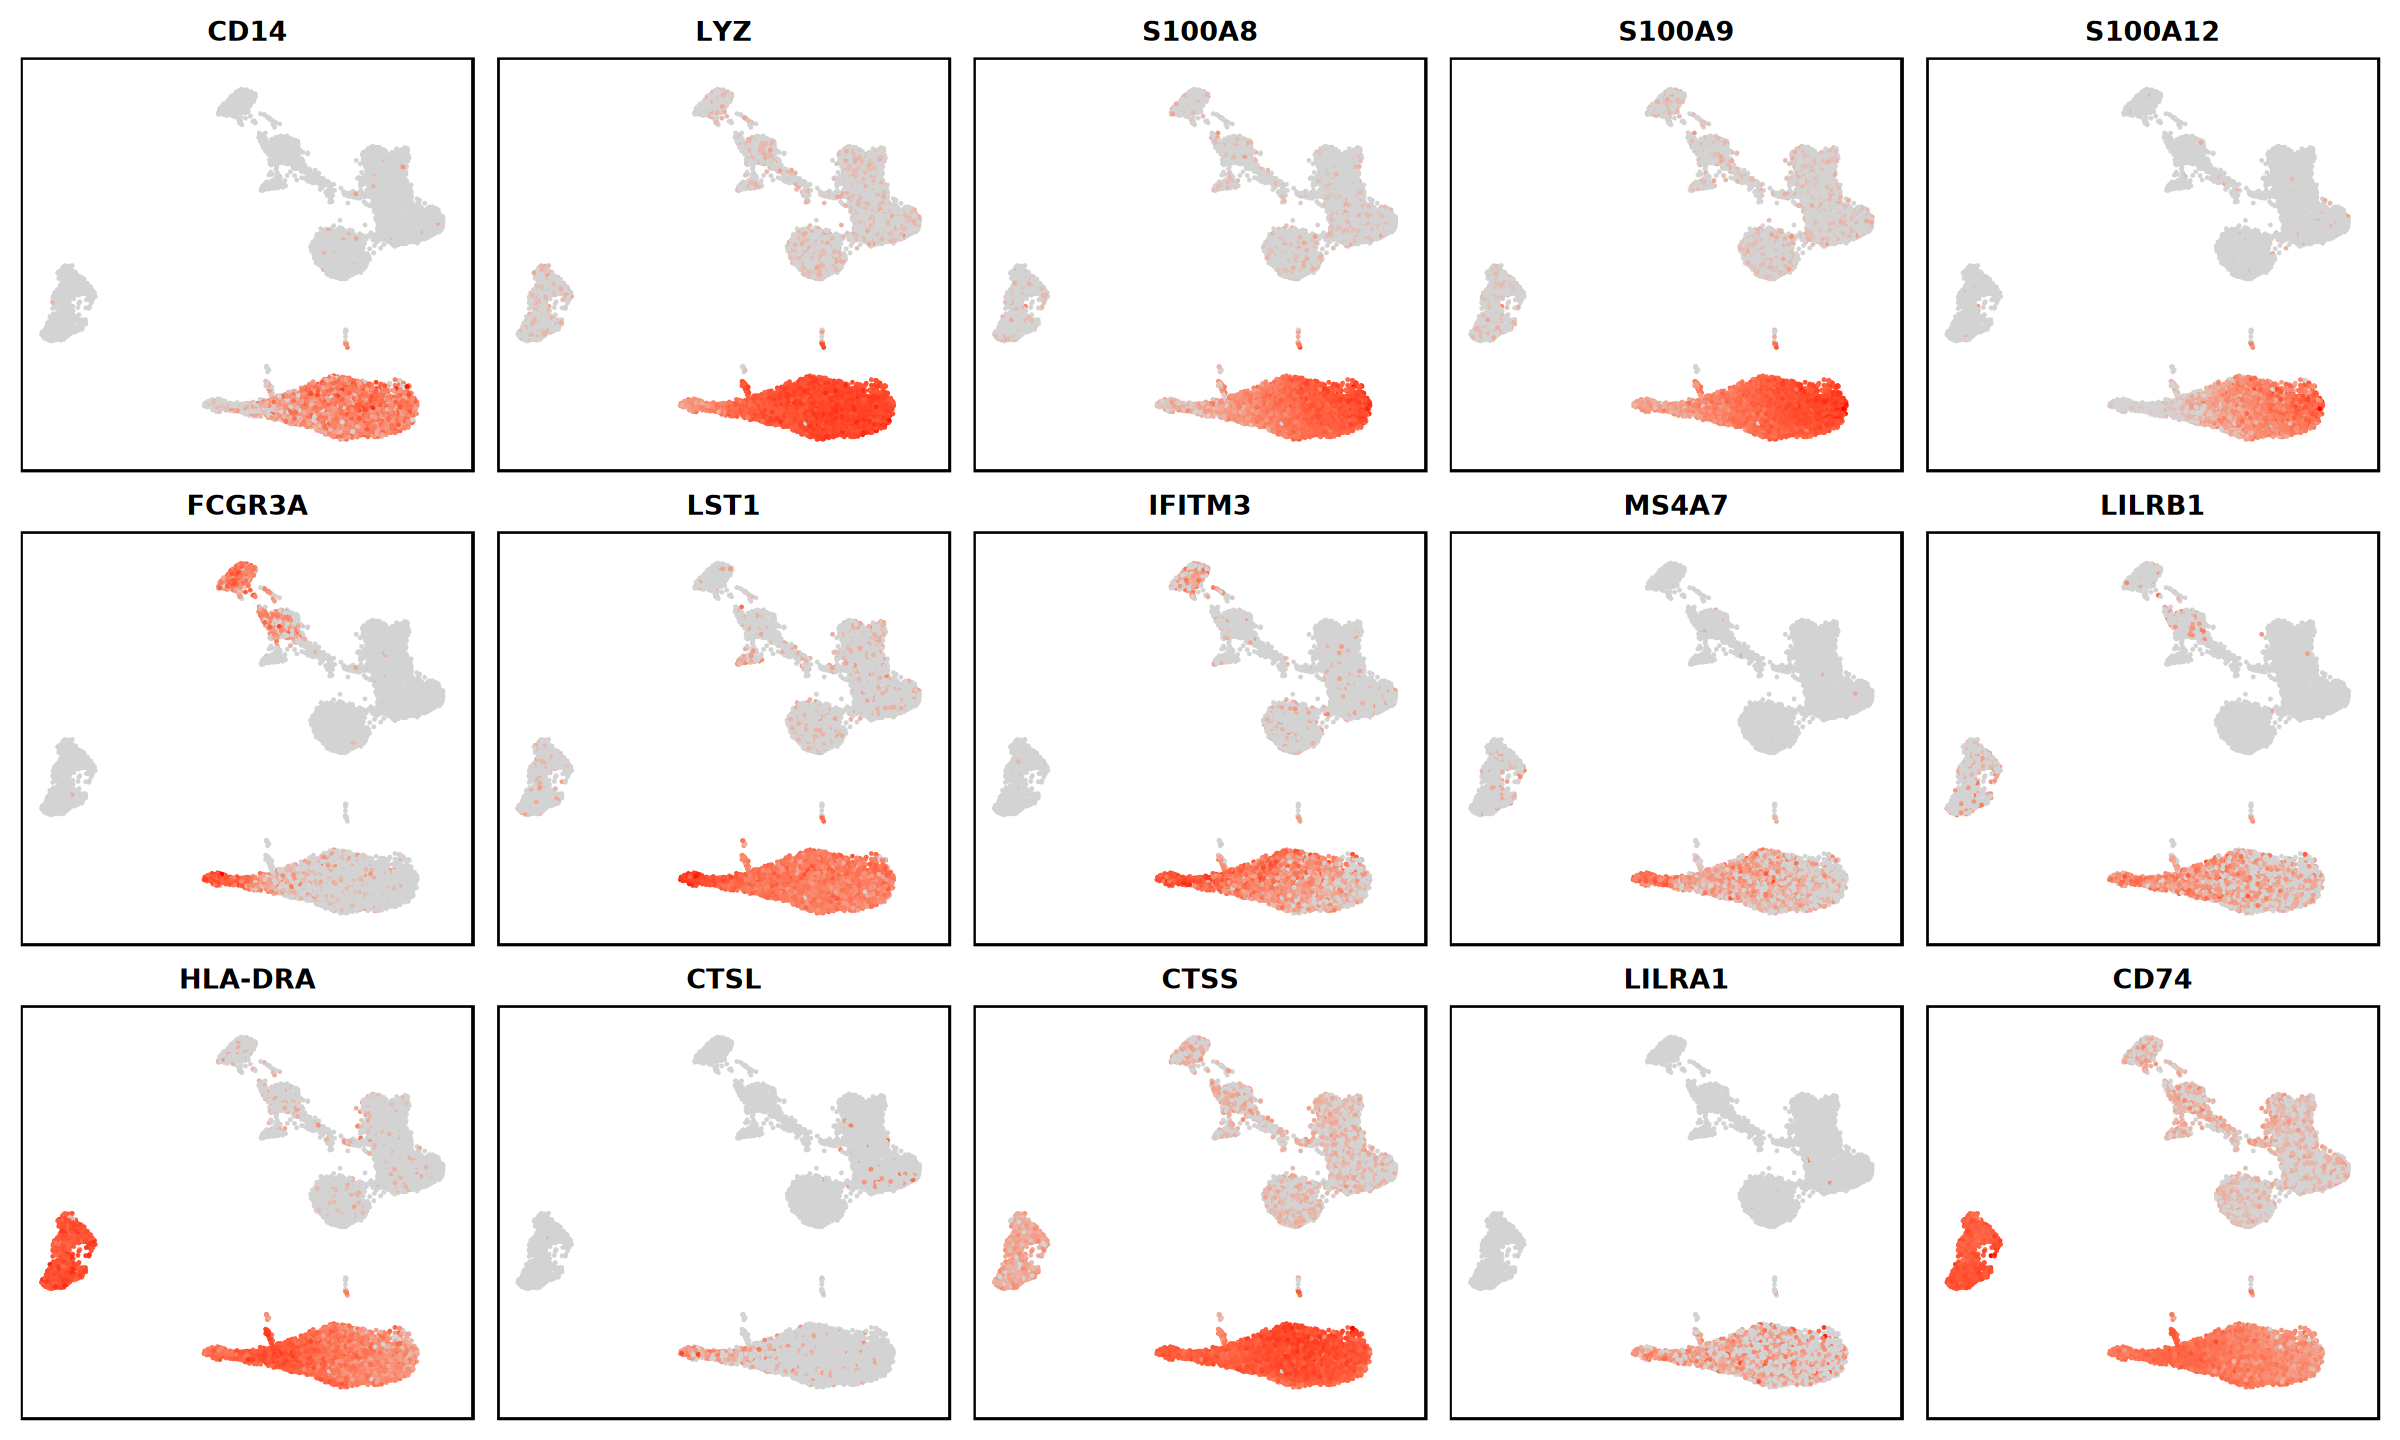

In [17]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

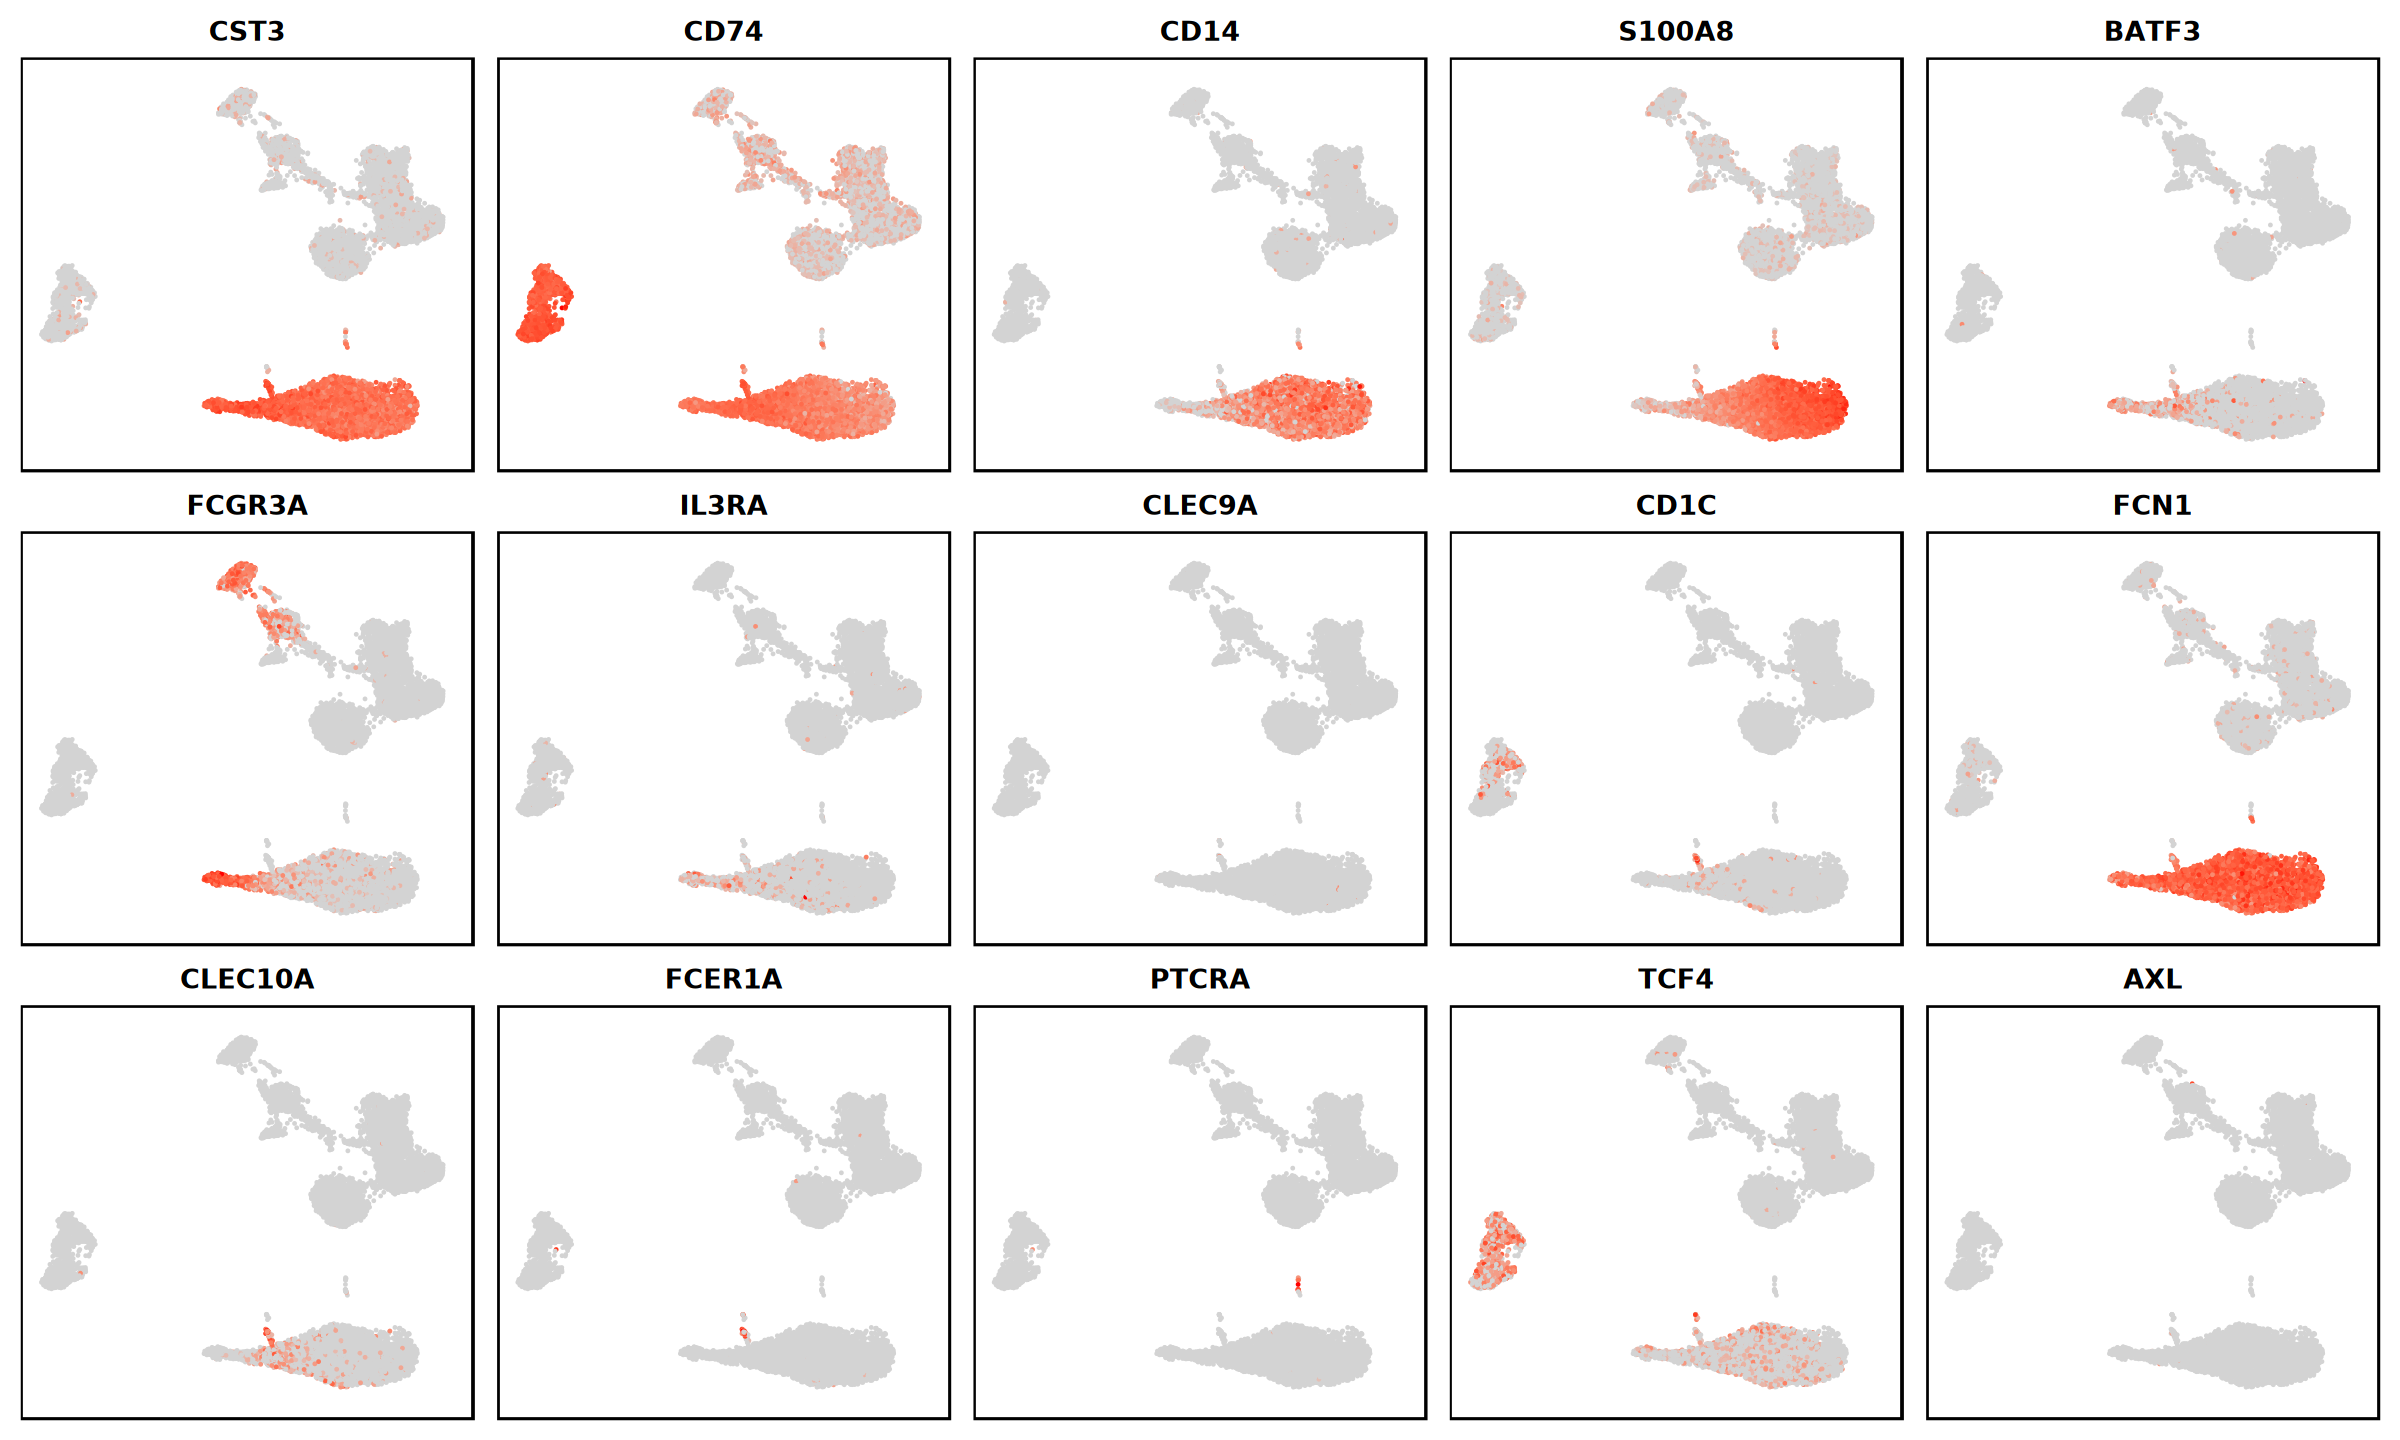

In [18]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "PTCRA", "SMIM5"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CST3", "CD74", "CD14", "S100A8", "BATF3", 
             "FCGR3A", "IL3RA", "CLEC9A", "CD1C", "FCN1",
             "CLEC10A", "FCER1A", "PTCRA", "TCF4", "AXL")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

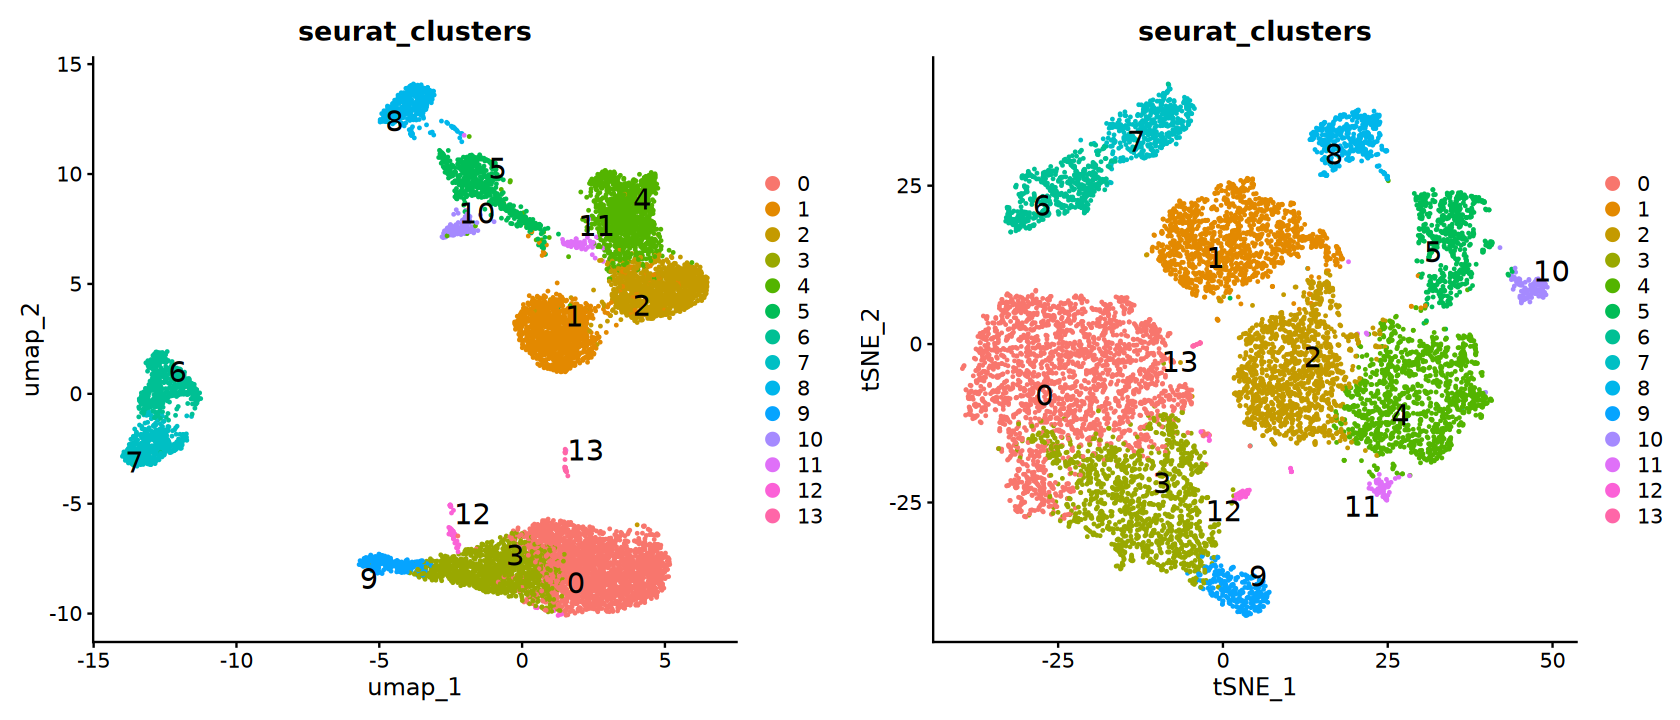

In [19]:
p1 <- DimPlot(
    scrna, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = TRUE)
p2 <- DimPlot(
    scrna, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = TRUE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [20]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Classical Monocytes", "1" = "Naïve/Memory CD8 T", "2" = "Naïve/Memory CD4 T",
    "3" = "Intermediate Monocytes", "4" = "Activated CD4 T", "5" = "Cytotoxic CD8 T",
    "6" = "Plasma Cells", "7" = "Naive B", "8" = "NK Cells",
    "9" = "Non-classical Monocytes", "10" = "MAIT", "11" = "Treg", 
    "12" = "Dendritic Cells (cDC2)", "13" = "Platelets")

In [21]:
scrna@meta.data$celltype <- 
    cluster2celltype[as.character(scrna$seurat_clusters)]

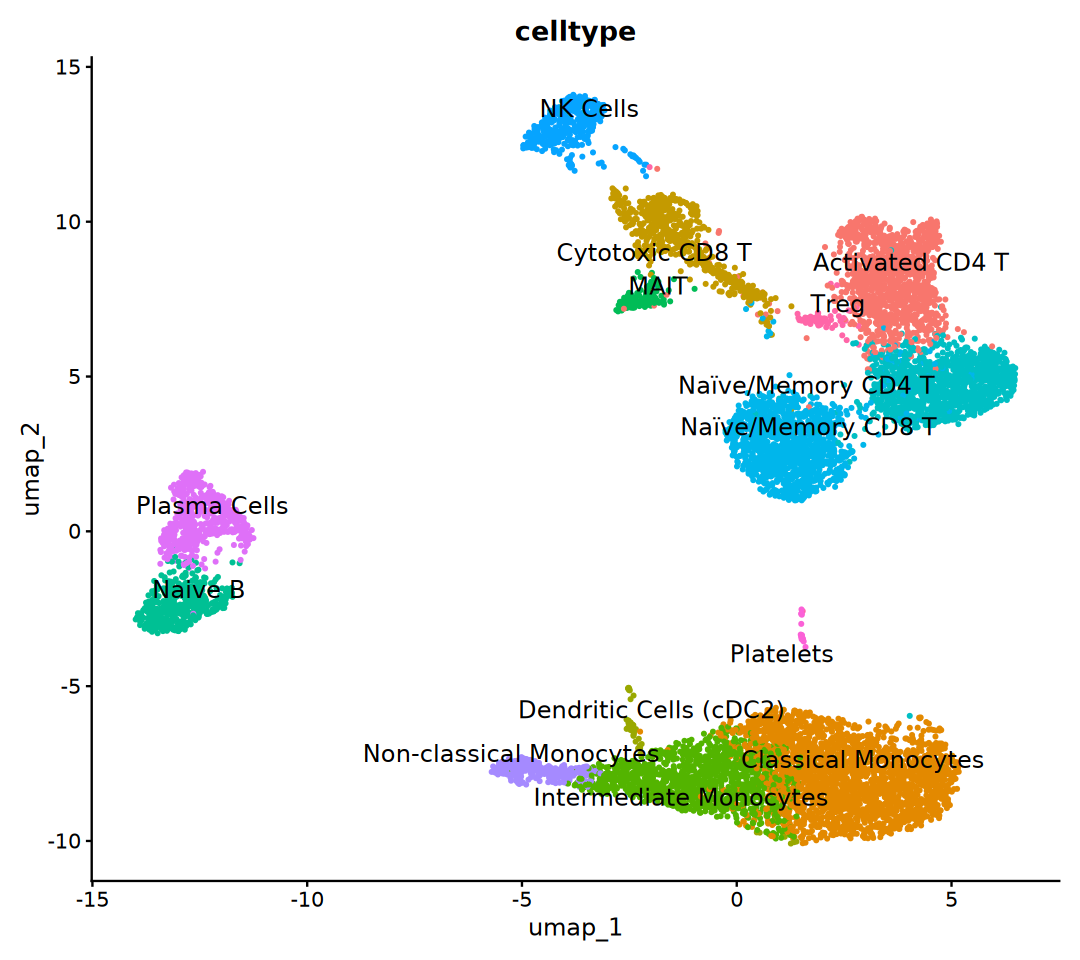

In [22]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(scrna, reduction = "umap", group.by = "celltype", 
        pt.size = 0.5, label = TRUE, repel = TRUE, label.size = 5) + 
    NoLegend()

### [Annotation of cell types (ACT)](http://xteam.xbio.top/ACT/)

In [ ]:
ACTresult <- file.path(
    data_dir, "result", "ACT_Annotation_results.txt") |>
    read.delim(header = TRUE)

In [ ]:
cellAnnoACT <- ACTresult |> 
    group_by(Cluster) |> 
    top_n(1, wt = -Padj)
cellAnnoACT

In [ ]:
cluster2celltype <- cellAnnoACT$Cell.Type
names(cluster2celltype) <- str_extract(cellAnnoACT$Cluster, "\\d+")

In [ ]:
scrna@meta.data$ACT_Anno <- 
    cluster2celltype[as.character(scrna$seurat_clusters)]

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(scrna, reduction = "umap", group.by = "ACT_Anno", 
        label = TRUE, repel = TRUE,
        pt.size = 0.5, label.size = 5) + 
    NoLegend()

In [91]:
scDat.markers |> 
    group_by(cluster) |> 
    dplyr::filter(avg_log2FC > 1) |> 
    dplyr::filter(p_val < 0.05) |> 
    top_n(30, wt = avg_log2FC) -> temp
temp <- temp[, c("cluster", "gene")]
df_summary <- temp %>%
  group_by(cluster) %>%
  summarise(value = paste(gene, collapse = ","))
df_summary$cluster <- paste0("cluster_", df_summary$cluster, ":")
write.table(df_summary, paste0(plotDir, "step06_3_topMarkerGenesForACTweb.csv"), row.names = F, col.names = F, sep = ",", quote = F)

In [92]:
ACTresult <- read.table(paste0(plotDir, "ACT_Annotation results_Stomach_top 10.txt"), header = T, sep = "\t")
cellAnnoACT <- ACTresult |> group_by(Cluster) |> arrange(Padj) |> slice_head(n = 1)
cellAnnoACT

Order,Cluster,Cell.Type,Padj,whg.p,gsea.p,Over.Markers.whg,Over.Markers.gsea,whg.overlap,gsea.overlap
<int>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<chr>,<chr>
1,cluster_0,"Effector memory CD4-positive, alpha-beta T cell",7.665132e-17,4.790708e-18,NA,3/26,0/1,"IL7R,MAL,AQP3",
1,cluster_1,"CD8-positive, alpha-beta cytotoxic T cell",3.876479e-85,1.211400e-86,NA,17/51,23/503,"CCL5,NKG7,GZMA,CD8A,CST7,GZMK,GZMH,TRGC2,CD8B,IFNG,LAG3,XCL2,EOMES,GZMB,ZNF683,TRGC1,TRDC","CCL5,NKG7,GZMA,CD8A,CST7,GZMK,GZMH,TRGC2,CD8B,IFNG,CRTAM,CTSW,LAG3,XCL2,CMC1,KLRG1,EOMES,GZMB,PPP2R2B,FCRL6,TRGC1,KLRC2,TRDC"
1,cluster_10,Fibroblast,3.026673e-14,1.568224e-16,NA,10/309,8/229,"SOD3,PDGFRA,COL14A1,SFRP2,MFAP4,SFRP4,FIBIN,TCF21,DIO2,COX4I2","ISLR,SOD3,PDGFRA,COL14A1,SFRP2,MFAP4,SFRP4,TCF21"
1,cluster_11,Natural killer cell,1.447767e-90,7.501385e-93,NA,19/150,20/136,"GNLY,NKG7,FGFBP2,GZMB,KLRD1,PRF1,GZMH,CX3CR1,KLRF1,ADGRG1,LAIR2,MYOM2,PTGDS,SPON2,NCR1,B3GAT1,NCAM1,KIR3DL2,KLRC3","GNLY,NKG7,FGFBP2,GZMB,KLRD1,PRF1,GZMH,CX3CR1,KLRF1,ADGRG1,C1orf21,S1PR5,FCRL6,PTGDS,SPON2,KLRC2,NCR1,NCAM1,TTC38,SH2D1B"
1,cluster_12,Germinal center B cell,1.119906e-03,2.901312e-05,NA,2/13,3/96,"SUGCT,AICDA","SERPINA9,SUGCT,AICDA"
1,cluster_13,Plasma cell,3.509578e-26,1.818434e-28,NA,5/64,7/153,"JCHAIN,MZB1,DERL3,IGHG1,IGKC","JCHAIN,MZB1,DERL3,TPD52,IGHG1,EAF2,IGKC"
1,cluster_14,Endothelial cell,1.952106e-61,1.011454e-63,NA,20/466,22/201,"ADGRL4,VWF,RAMP2,PLVAP,CDH5,CLEC14A,EMCN,ECSCR,RAMP3,CLDN5,KDR,TM4SF18,SLCO2A1,TEK,ACKR1,SOX17,CCL14,SELE,FCN3,APLN","ADGRL4,VWF,RAMP2,PLVAP,CDH5,SOX18,CLEC14A,PCDH17,EMCN,ECSCR,RAMP3,PCAT19,CYYR1,CLDN5,KDR,TM4SF18,MYCT1,SLCO2A1,TEK,ACKR1,CCL14,SELE"
1,cluster_15,Naive B cell,2.562086e-37,2.655012e-39,NA,5/22,10/129,"IGHD,TCL1A,FCER2,CD19,CR2","CD79A,TNFRSF13C,IGHD,TCL1A,FCER2,LINC00926,CD19,FCRLA,CD72,HLA-DOB"
1,cluster_16,Mast cell,1.390454e-108,7.204422e-111,NA,16/61,17/212,"TPSAB1,TPSB2,CPA3,MS4A2,GATA2,KIT,VWA5A,HPGDS,IL1RL1,SLC18A2,HDC,TPSD1,SIGLEC8,ENPP3,CTSG,SIGLEC6","TPSAB1,TPSB2,CPA3,MS4A2,GATA2,KIT,VWA5A,HPGDS,IL1RL1,SLC18A2,HDC,RHEX,GCSAML,TPSD1,ADCYAP1,ENPP3,CTSG"


In [93]:
cellAnnoACT.test <- cellAnnoACT$Cell.Type
names(cellAnnoACT.test) <- str_split(cellAnnoACT$Cluster, "_", simplify = T)[,2]
cellAnnoACT.test

0 
"Effector memory CD4-positive, alpha-beta T cell" 
                                                1 
      "CD8-positive, alpha-beta cytotoxic T cell" 
                                               10 
                                     "Fibroblast" 
                                               11 
                            "Natural killer cell" 
                                               12 
                         "Germinal center B cell" 
                                               13 
                                    "Plasma cell" 
                                               14 
                               "Endothelial cell" 
                                               15 
                                   "Naive B cell" 
                                               16 
                                      "Mast cell" 
                                               17 
      "CD8-positive, alpha-beta cytotoxic T cell" 
                                                2 
                                   "Naive B cell" 
                                                3 
                                     "Neutrophil" 
                                                4 
                                               NA 
                                                5 
                              "Regulatory T cell" 
                                                6 
                                "Epithelial cell" 
                                                7 
                    "Tumor-associated macrophage" 
                                                8 
                                    "Plasma cell" 
                                                9 
                            "Natural killer cell"

In [94]:
temp <- scDat.integrate
Idents(temp) <- temp$seurat_clusters
temp <- RenameIdents(temp, cellAnnoACT.test)
temp

An object of class Seurat 
26093 features across 42968 samples within 1 assay 
Active assay: RNA (26093 features, 3000 variable features)
 3 layers present: data, counts, scale.data
 6 dimensional reductions calculated: pca, integrated.cca, integrated.cca.sampleTree, harmony, umap, tsne

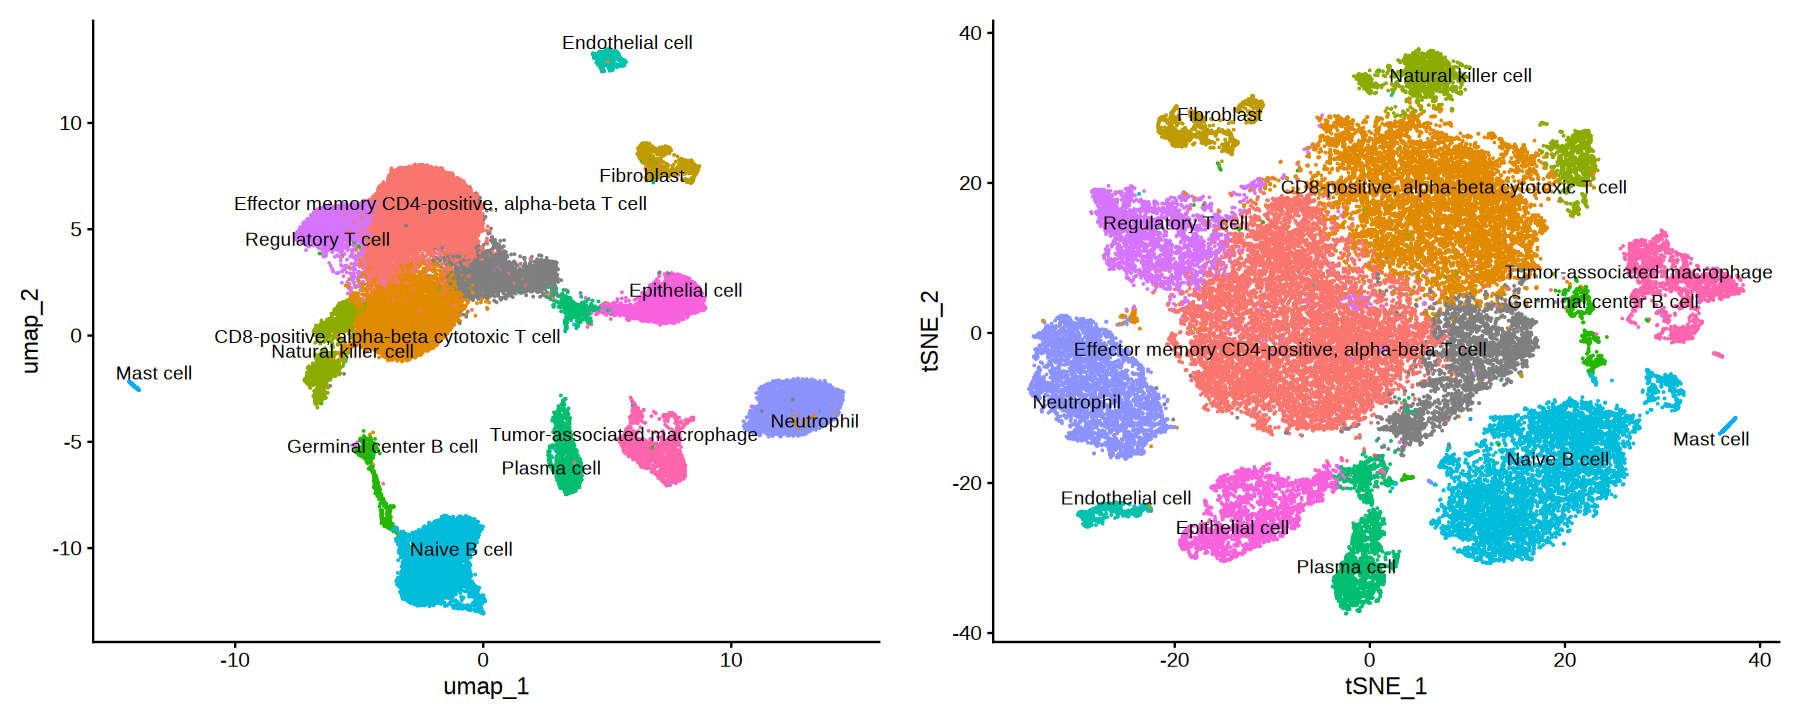

In [95]:
options(repr.plot.width = 15, repr.plot.height = 6)
p1 <- DimPlot(temp, reduction = "umap", label = T, repel = T) + NoLegend()
p2 <- DimPlot(temp, reduction = "tsne", label = T, repel = T) + NoLegend()
p <- plot_grid(p1, p2, ncol = 2)
print(p)
ggsave(paste0(plotDir, "step06_4_cellAnnotation_ACTwebResult.pdf"), p, width = 15, height = 6)

## b). Automatic (Reference Markers)

### [scCATCH](https://github.com/ZJUFanLab/scCATCH)

In [23]:
suppressPackageStartupMessages(library(scCATCH))

In [24]:
# exprmat <- GetAssayData(scrna, slot = "RNA", layer = "data")
exprmat <- LayerData(scrna, assay = "RNA", layer = "data")

In [25]:
celltype.scCATCH <- createscCATCH(
    data = exprmat, cluster = as.character(scrna$seurat_clusters))

In [26]:
# find marker gene for each cluster
celltype.scCATCH <- findmarkergene(
    celltype.scCATCH, species = "Human", marker = cellmatch, 
    tissue = c("Blood", "Peripheral blood", "Plasma", "Serum", "Umbilical cord blood"), 
    verbose = FALSE)

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.7 GiB”
There are 2993 potential marker genes in CellMatch database for Human on Blood, Peripheral blood, Plasma, Serum, Umbilical cord blood.



In [27]:
# find cell type for each cluster
celltype.scCATCH <- findcelltype(celltype.scCATCH)

In [28]:
scrna$celltype.scCATCH <-
  celltype.scCATCH@celltype$cell_type[
      match(as.character(scrna$seurat_clusters), 
            celltype.scCATCH@celltype$cluster)
  ]

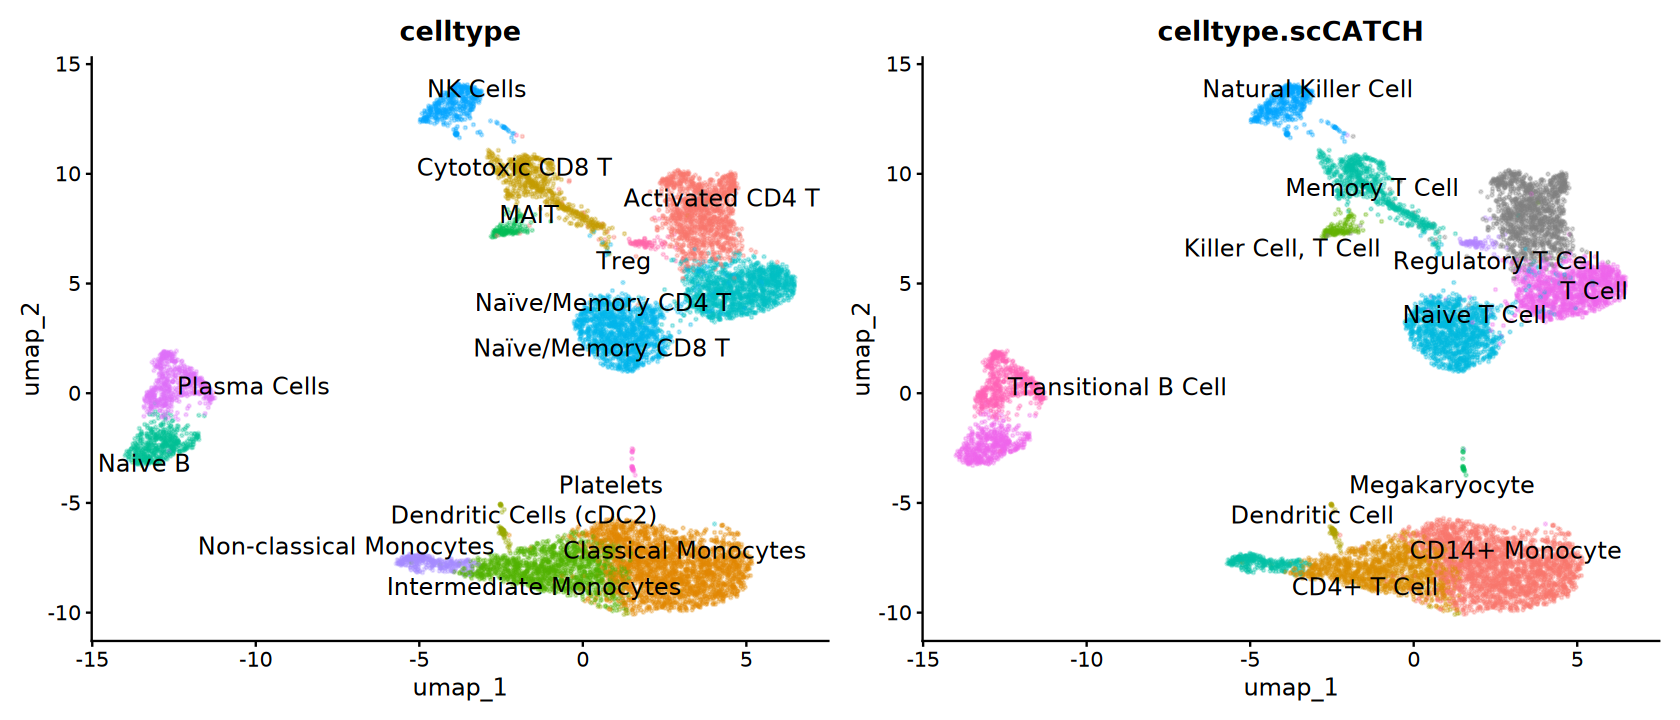

In [29]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(scrna, reduction = "umap",
        group.by = c("celltype", "celltype.scCATCH"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3,  ncol = 2) &
    NoLegend()

### [ScType](https://github.com/IanevskiAleksandr/sc-type)

In [30]:
suppressPackageStartupMessages(library(HGNChelper))

In [31]:
source("~/software/R/sc-type/R/gene_sets_prepare.R")
source("~/software/R/sc-type/R/sctype_score_.R")

In [32]:
# DB file
db_ <- "~/software/R/sc-type/ScTypeDB_full.xlsx"
# db_ <- "~/software/R/sc-type/ScTypeDB_short.xlsx"

tissue <- "Immune system"

# prepare gene sets
suppressWarnings(
    gs_list <- gene_sets_prepare(db_, tissue)
)

In [33]:
# exprmatsd <- GetAssayData(scrna, slot = "RNA", layer = "scale.data")
exprmatsd <- LayerData(scrna, assay = "RNA", layer = "scale.data")

In [34]:
# run ScType
es.max <- sctype_score(
    scRNAseqData = exprmatsd, scaled = TRUE, 
    gs = gs_list$gs_positive, gs2 = gs_list$gs_negative)

In [35]:
es.max[1:6, 1:6]

,AAACCCAAGTAATACG-1,AAACCCAAGTCACACT-1,AAACCCACAAAGCGTG-1,AAACCCACAATCGAAA-1,AAACCCACAGATCACT-1,AAACCCACATTGACCA-1
Pro-B cells,0.9670646,-0.28537076,-0.51239266,1.7925615,4.1610560,-0.7471976
Pre-B cells,-0.1606381,-0.32175800,-0.53268695,1.5879209,5.2562788,0.2898434
Naive B cells,-0.3041788,0.12067926,-0.44698899,1.6086250,6.1216813,-0.9772458
Memory B cells,-0.4180113,0.03726131,-0.32490949,1.8121086,5.8798051,-1.0556499
Plasma B cells,-0.1186296,0.46301526,-0.07791467,-0.8004963,2.1135872,-0.7216814
Naive CD8+ T cells,-2.1479976,-1.26945653,1.29894586,-0.3643930,-0.9107431,-2.9322008


In [36]:
cl_resutls <- scrna@meta.data |>
    rownames_to_column("cell") |>
    select(cell, cluster = seurat_clusters) |>
    group_split(cluster) |>
    map_dfr(function(df) {
        cl <- unique(df$cluster)
        cells <- df$cell
        es.max.cl <- es.max[, cells, drop = FALSE] |>
            rowSums() |>
            sort(decreasing = TRUE)
        tibble(cluster = cl, type = names(es.max.cl),
               scores = unname(es.max.cl), ncells = length(cells)) |>
        slice_head(n = 5)
    })

In [37]:
head(cl_resutls)

cluster,type,scores,ncells
<fct>,<chr>,<dbl>,<int>
0,Classical Monocytes,5801.978,2379
0,Macrophages,4290.136,2379
0,Neutrophils,3953.729,2379
0,Non-classical monocytes,3766.942,2379
0,Intermediate monocytes,3328.263,2379
1,Naive CD8+ T cells,3139.990,1329


In [41]:
celltype.ScType <- cl_resutls |>
    group_by(cluster) |>
    slice_max(order_by = scores, n = 1, with_ties = FALSE) |>
    ungroup() |>
    mutate(type = if_else(scores < ncells / 4, "Unknown", type))

In [42]:
suppressPackageStartupMessages(library(igraph))
suppressPackageStartupMessages(library(ggraph))
suppressPackageStartupMessages(library(RColorBrewer))

In [43]:
ccolss <- colorRampPalette(brewer.pal(12, "Set3"))(
    length(unique(cl_resutls$cluster)))

In [44]:
# Prepare edges
edges <- cl_resutls |>
    arrange(cluster, -scores) |>
    mutate(from = paste0("cluster ", cluster),
           to = paste0(type, "_", cluster)) |>
    select(from, to)
# Prepare level-1 nodes (clusters)
nodes_lvl1 <- celltype.ScType |>
    transmute(cluster = paste0("cluster ", cluster), 
              ncells = ncells,
              Colour = "#f1f1ef", 
              ord = 1,
              realname = cluster)
# Prepare level-2 nodes (cell types)
nodes_lvl2 <- cl_resutls |>
    mutate(cluster_id = cluster,
           cluster = paste0(type, "_", cluster),
           Colour = ccolss[as.integer(factor(cluster_id))],
           ord = 2,
           realname = type,
           ncells = pmax(scores, 1)) |>
    select(cluster, ncells, Colour, ord, realname)
# merge nodes
nodes <- bind_rows(nodes_lvl1, nodes_lvl2)

In [46]:
cell_map <- openxlsx::read.xlsx(db_) |> distinct(cellName, shortName)

nodes <- nodes |>
    left_join(cell_map, by = c("realname" = "cellName")) |>
    mutate(shortName = ifelse(is.na(shortName), realname, shortName))

In [47]:
# Build graph
g <- igraph::graph_from_data_frame(edges, vertices = nodes)

Non-leaf weights ignored


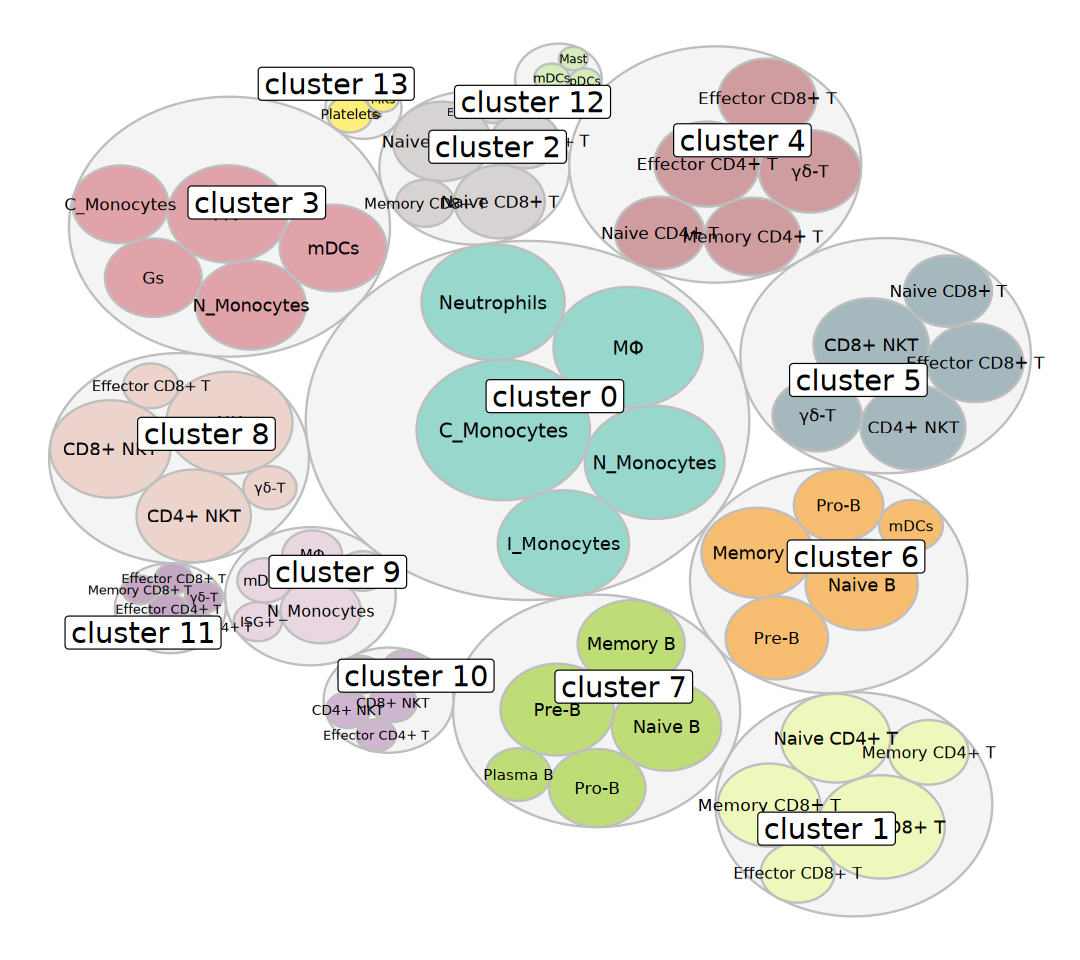

In [50]:
options(repr.plot.width = 9, repr.plot.height = 8)
ggraph(g, layout = 'circlepack', weight = I(ncells)) + 
    geom_node_circle(
        aes(filter = ord == 1, fill = I("grey95"), 
            colour = I("grey")), alpha = 0.9) + 
    geom_node_circle(
        aes(filter = ord == 2, fill = I(Colour), 
            colour = I("grey")), alpha = 0.9) +
    geom_node_text(
        aes(filter = ord == 2, label = shortName, colour = I("black"), 
            size = I(log(ncells, 25) * 1.5)), repel = FALSE) +
    geom_node_label(
        aes(filter = ord == 1, label = realname,
            colour = I("black"), fill = I("white"), size = I(6)), 
        repel = TRUE, segment.linetype = "dotted") +
    theme_void()

In [51]:
scrna$celltype.ScType <-
  celltype.ScType$type[
      match(as.character(scrna$seurat_clusters), 
            celltype.ScType$cluster)
  ]

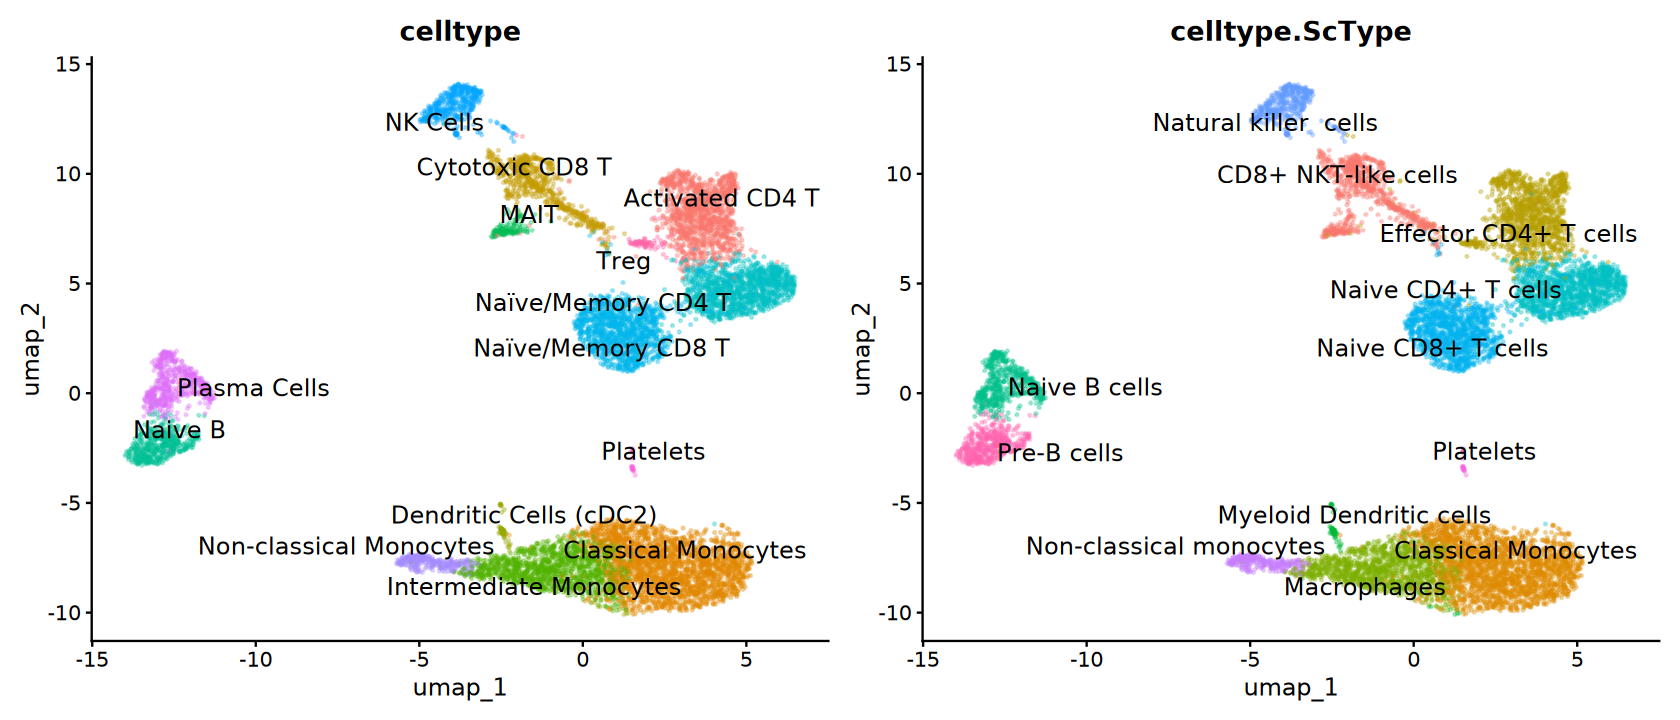

In [52]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(scrna, reduction = "umap",
        group.by = c("celltype", "celltype.ScType"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3,  ncol = 2) &
    NoLegend()

In [53]:
# source("~/software/R/sc-type/R/sctype_wrapper.R")
# source("~/software/R/sc-type/R/gene_sets_prepare.R")

# es.max <- run_sctype(
#     scrna, assay = "RNA", scaled = TRUE, 
#     known_tissue_type = "Immune system",
#     custom_marker_file = "reference/sc-type/ScTypeDB_short.xlsx",
#     name = "ScType.celltype")

## c). Automatic (Reference Data)

### [SingleR](https://github.com/SingleR-inc/SingleR)

In [54]:
suppressPackageStartupMessages(library(SingleR))
suppressPackageStartupMessages(library(celldex))

In [78]:
# Possible network problems
datasets <- surveyReferences()
datasets$title |> cat(sep = "\n")

Human bulk RNA-seq data from DICE
Human bulk RNA-seq data from Blueprint and ENCODE
Mouse microarray expression from the Immunologic Genome Project
Bulk RNA-seq data of sorted mouse cell populations
Microarray data from the Human Primary Cell Atlas
Bulk microarray expression of sorted hematopoietic cells from Novershtern et al.
Human bulk RNA-seq data from Monaco et al.


In [56]:
# refAnno <- celldex::DatabaseImmuneCellExpressionData(ensembl = FALSE)
refAnno <- fetchReference("dice", "2024-02-26", realize.assays = TRUE)
refAnno

class: SummarizedExperiment 
dim: 48043 1561 
metadata(0):
assays(1): logcounts
rownames(48043): 5S_rRNA 7SK ... ZZEF1 ZZZ3
rowData names(0):
colnames(1561): TPM_1 TPM_2 ... TPM_101 TPM_102
colData names(3): label.main label.fine label.ont

In [57]:
colData(refAnno)

DataFrame with 1561 rows and 3 columns
           label.main             label.fine   label.ont
          <character>            <character> <character>
TPM_1         B cells         B cells, naive  CL:0000788
TPM_2         B cells         B cells, naive  CL:0000788
TPM_3         B cells         B cells, naive  CL:0000788
TPM_4         B cells         B cells, naive  CL:0000788
TPM_5         B cells         B cells, naive  CL:0000788
...               ...                    ...         ...
TPM_98  T cells, CD8+ T cells, CD8+, naive..  CL:0000906
TPM_99  T cells, CD8+ T cells, CD8+, naive..  CL:0000906
TPM_100 T cells, CD8+ T cells, CD8+, naive..  CL:0000906
TPM_101 T cells, CD8+ T cells, CD8+, naive..  CL:0000906
TPM_102 T cells, CD8+ T cells, CD8+, naive..  CL:0000906

In [58]:
# exprmat <- GetAssayData(scrna, slot = "RNA", layer = "data")
exprmat <- LayerData(scrna, assay = "RNA", layer = "data")

In [59]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- SingleR(
    test = exprmat, ref = refAnno, labels = refAnno$label.main,
    clusters = scrna$seurat_clusters, de.method = "classic")

In [60]:
head(celltype.SingleR)

DataFrame with 6 rows and 4 columns
                          scores        labels delta.next pruned.labels
                        <matrix>   <character>  <numeric>   <character>
0 0.181357:0.910870:0.260770:...     Monocytes  0.6500992     Monocytes
1 0.141143:0.200308:0.376565:... T cells, CD8+  0.0868362 T cells, CD8+
2 0.147511:0.241349:0.356424:... T cells, CD4+  0.1428208 T cells, CD4+
3 0.210630:0.904009:0.263056:...     Monocytes  0.6409525     Monocytes
4 0.124146:0.267258:0.494097:... T cells, CD4+  0.1633128 T cells, CD4+
5 0.050840:0.277550:0.744832:...      NK cells  0.1647704      NK cells

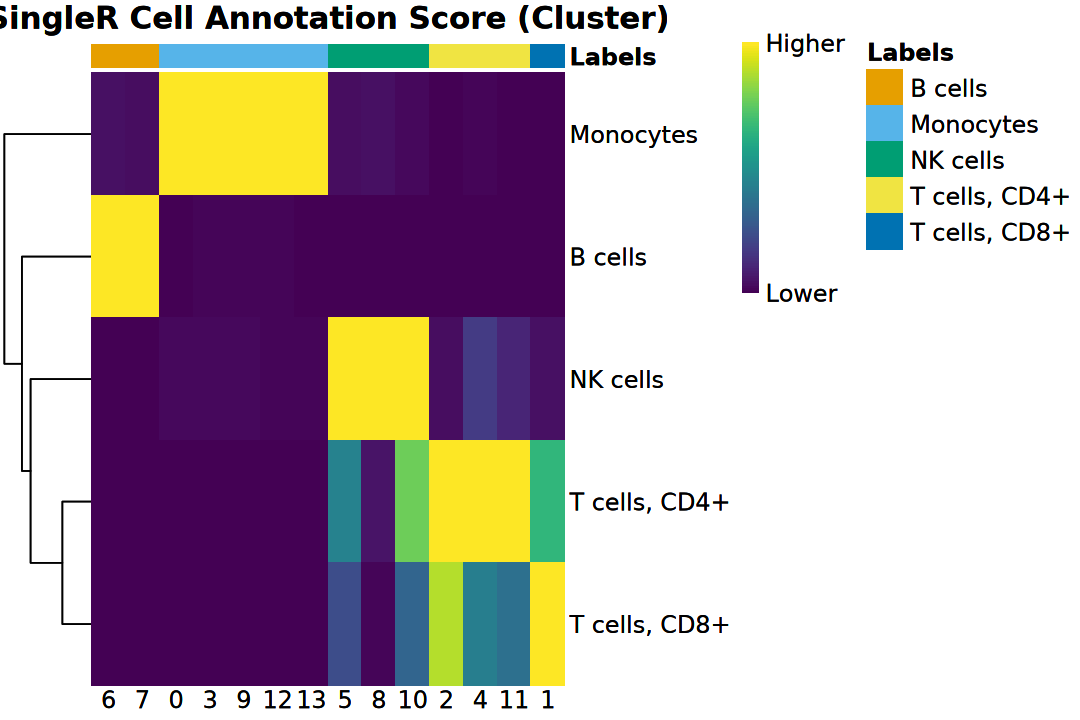

In [61]:
options(repr.plot.width = 9, repr.plot.height = 6)
plotScoreHeatmap(celltype.SingleR, 
                 main = "SingleR Cell Annotation Score (Cluster)",
                 show_colnames = TRUE, angle_col = 0, 
                 fontsize = 14)

In [62]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR.fine <- SingleR(
    test = exprmat, ref = refAnno, labels = refAnno$label.fine,
    clusters = scrna$seurat_clusters, de.method = "classic")

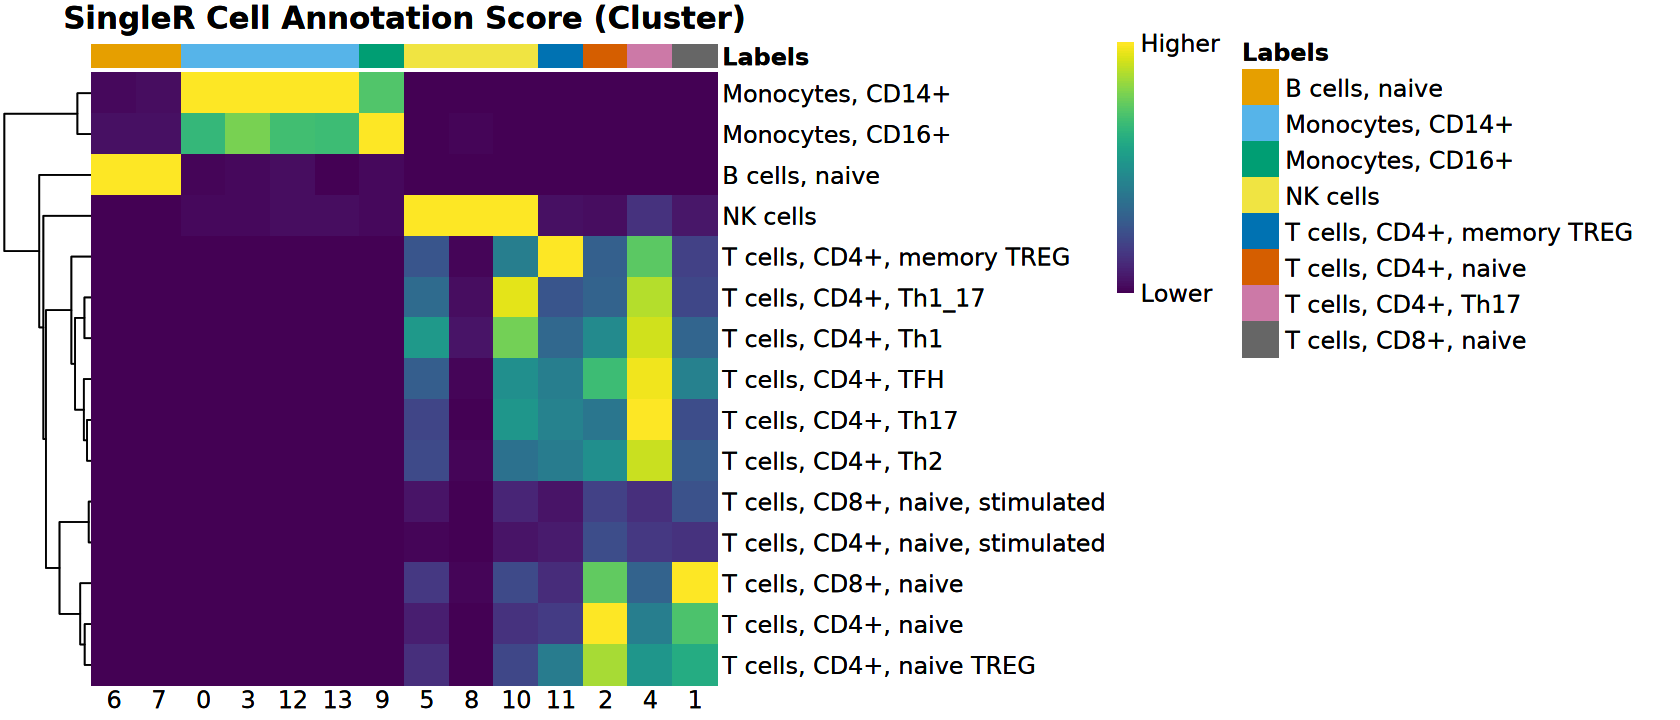

In [63]:
options(repr.plot.width = 14, repr.plot.height = 6)
plotScoreHeatmap(celltype.SingleR.fine, 
                 main = "SingleR Cell Annotation Score (Cluster)",
                 show_colnames = TRUE, angle_col = 0, 
                 fontsize = 14)

In [64]:
# SingleR performs the prediction of celltypes for each cell
celltype.cell.SingleR <- SingleR(
    test = exprmat, ref = refAnno, labels = refAnno$label.main,
    de.method = "classic")

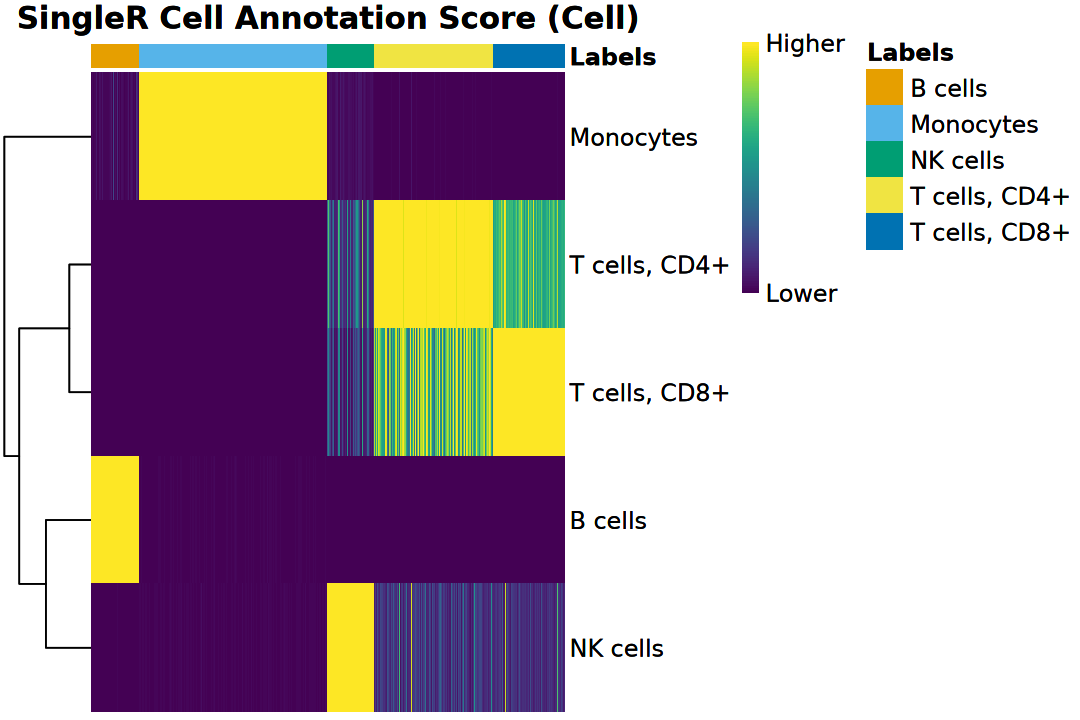

In [65]:
options(repr.plot.width = 9, repr.plot.height = 6)
plotScoreHeatmap(celltype.cell.SingleR, 
                 main = "SingleR Cell Annotation Score (Cell)",
                 fontsize = 14)

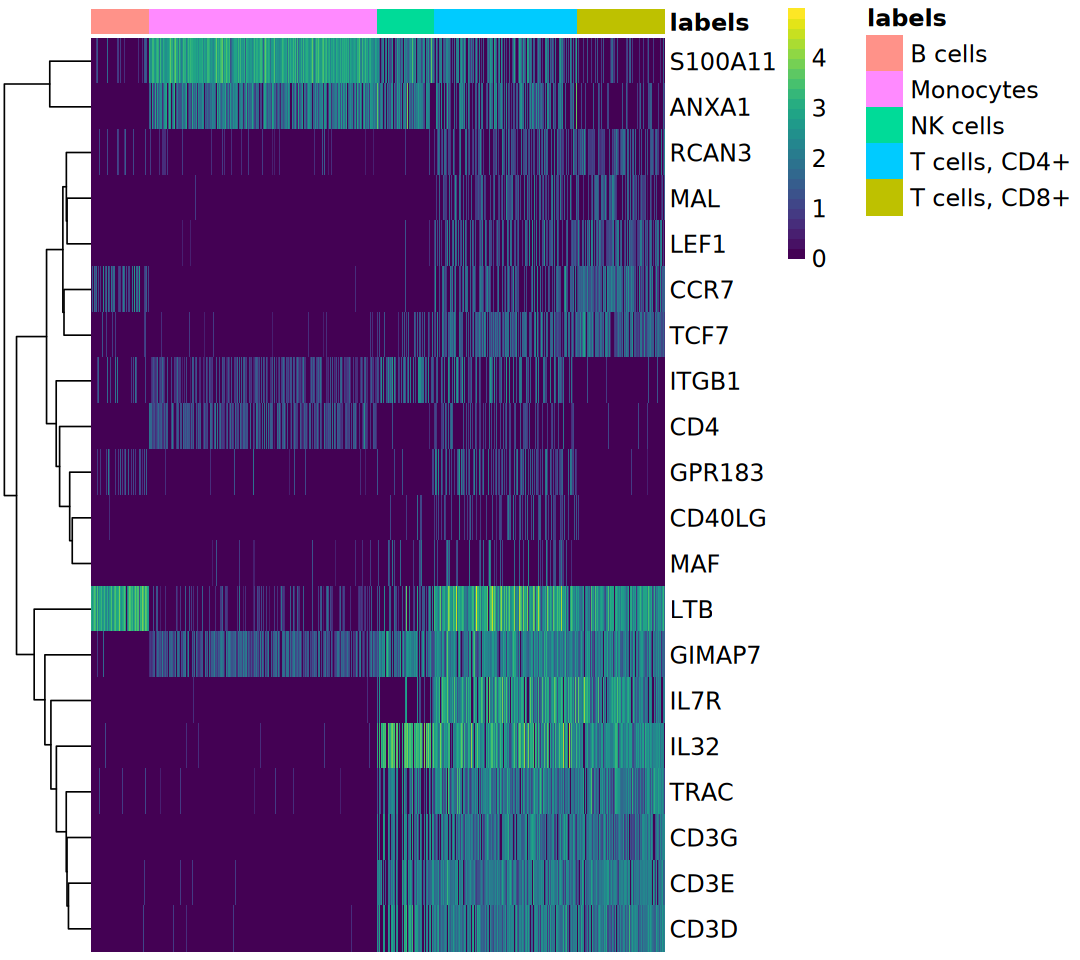

In [66]:
options(repr.plot.width = 9, repr.plot.height = 8)
plotMarkerHeatmap(celltype.cell.SingleR, exprmat, 
                  label = "T cells, CD4+", fontsize = 14)

In [67]:
scrna$celltype.SingleR <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

scrna$celltype.SingleR.fine <- 
    celltype.SingleR.fine$labels[scrna$seurat_clusters]

scrna$celltype.cell.SingleR <- celltype.cell.SingleR$labels

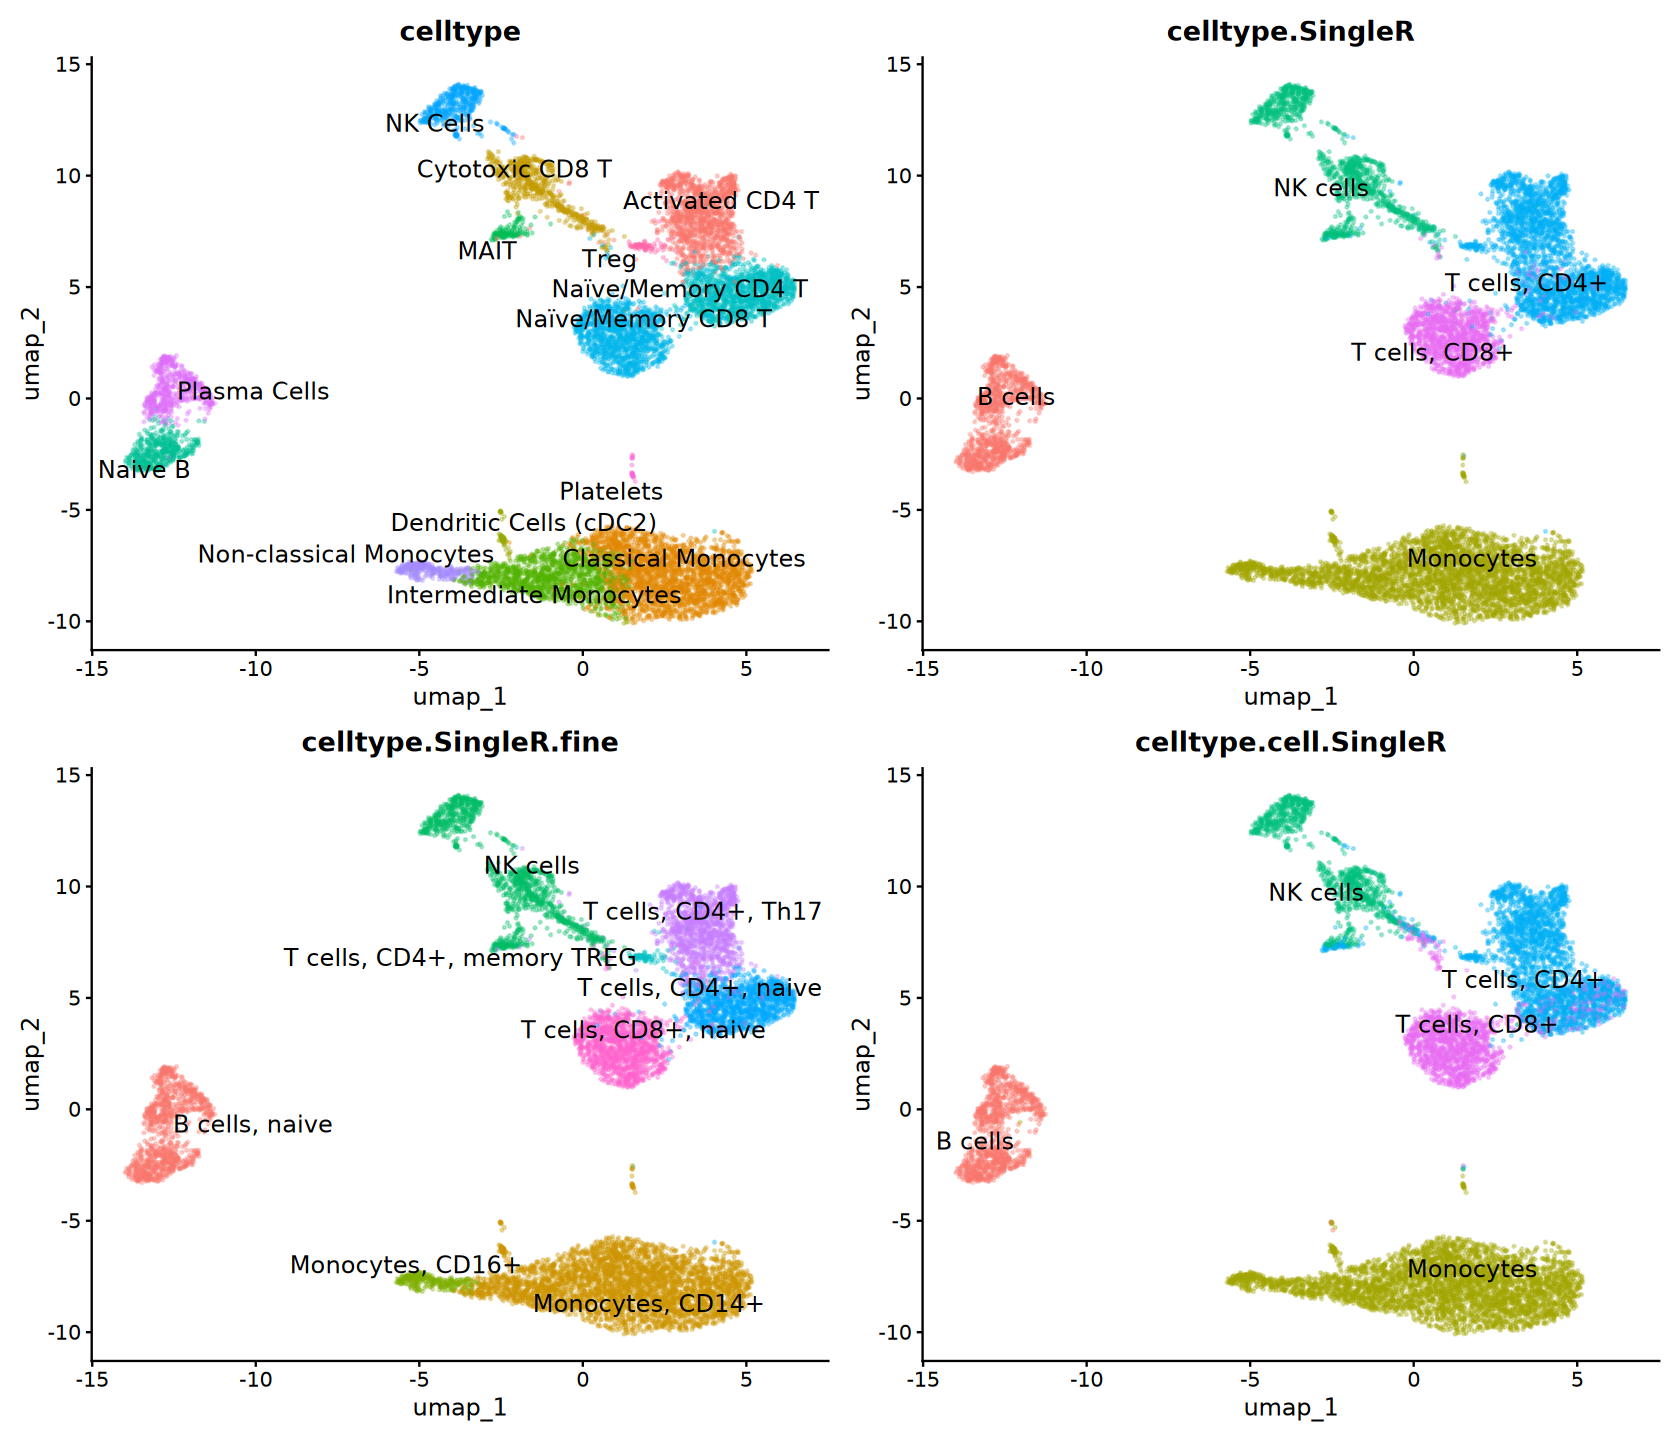

In [68]:
options(repr.plot.width = 14, repr.plot.height = 12)
DimPlot(scrna, reduction = "umap",
        group.by = c(
            "celltype", "celltype.SingleR", "celltype.SingleR.fine",
            "celltype.cell.SingleR"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3,  ncol = 2) &
    NoLegend()

In [ ]:
# single-cell dataset
# refAnno <- readRDS()

In [ ]:
# # SingleR performs the prediction of celltypes for each cluster
# celltype.SingleR <- SingleR(
#     test = sce, ref = refAnno, labels = refAnno$label.fine, 
#     de.method = "wilcox")

### [scHCL](https://github.com/ggjlab/scHCL) or [scMCA](https://github.com/ggjlab/scMCA)

In [82]:
suppressPackageStartupMessages(library(scHCL))
# suppressPackageStartupMessages(library(scMCA))
suppressPackageStartupMessages(library(pheatmap))

In [83]:
# exprmat <- GetAssayData(scrna, slot = "RNA", layer = "counts")
exprmat <- LayerData(scrna, assay = "RNA", layer = "counts")

In [86]:
celltype.scHCL <- scHCL(scdata = exprmat, numbers_plot = 3)

In [87]:
str(celltype.scHCL)

List of 4
 $ cors_matrix    : num [1:1841, 1:10232] 0.395 0.251 0.352 0.335 0.349 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : chr [1:1841] "M2.Macrophage.Adult.Adipose1." "Stromal.cell.Adult.Adipose1." "Adipocyte_SPP1.high.Adult.Adipose1." "Mast.cell.Adult.Adipose1." ...
  .. ..$ : chr [1:10232] "AAACCCAAGTAATACG-1" "AAACCCAAGTCACACT-1" "AAACCCACAAAGCGTG-1" "AAACCCACAATCGAAA-1" ...
 $ top_cors       : num 3
 $ scHCL          : Named chr [1:10232] "MO.Placenta_VentoTormo." "MO.Placenta_VentoTormo." "T.cells1.Placenta_VentoTormo." "B.cell..Centrocyte..Adult.Peripheral.Blood4." ...
  ..- attr(*, "names")= chr [1:10232] "AAACCCAAGTAATACG-1" "AAACCCAAGTCACACT-1" "AAACCCACAAAGCGTG-1" "AAACCCACAATCGAAA-1" ...
 $ scHCL_probility:'data.frame':	30696 obs. of  3 variables:
  ..$ Cell     : Factor w/ 10232 levels "AAACCCAAGTAATACG-1",..: 1 1 1 2 2 2 3 3 3 4 ...
  ..$ Cell type: Factor w/ 73 levels "B.cell..Plasmocyte._IGLV3.1.high.Adult.Ascending.Colon1.",..: 20 37 68 20 37 68 62 64 66 18 .

In [91]:
# options(repr.plot.width = 9, repr.plot.height = 8)
# pheatmap(celltype.scHCL$cors_matrix, 
#          show_colnames = FALSE, 
#          show_rownames = FALSE)

In [95]:
celltype.scHCL$scHCL.simple <- dplyr::case_when(
    grepl("^T.cells", celltype.scHCL$scHCL) ~ "T cell",
    grepl("^B.cell|^Small.pre.B.cell", celltype.scHCL$scHCL) ~ "B cell",
    grepl("^Plasma|Plasmocyte", celltype.scHCL$scHCL) ~ "Plasma cell",
    grepl("^Blood.NK", celltype.scHCL$scHCL) ~ "NK cell",
    grepl("^MO\\.|^Macrophage", celltype.scHCL$scHCL) ~ "Myeloid",
    grepl("^Megakaryocyte", celltype.scHCL$scHCL) ~ "Megakaryocyte",
    grepl("Haematopoietic.Stem.Cell|progenitor", celltype.scHCL$scHCL) ~ "HSPC",
    grepl("^Proliferating", celltype.scHCL$scHCL) ~ "Proliferating",
    TRUE ~ "Other"
)

In [96]:
scrna$celltype.scHCL <- celltype.scHCL$scHCL.simple

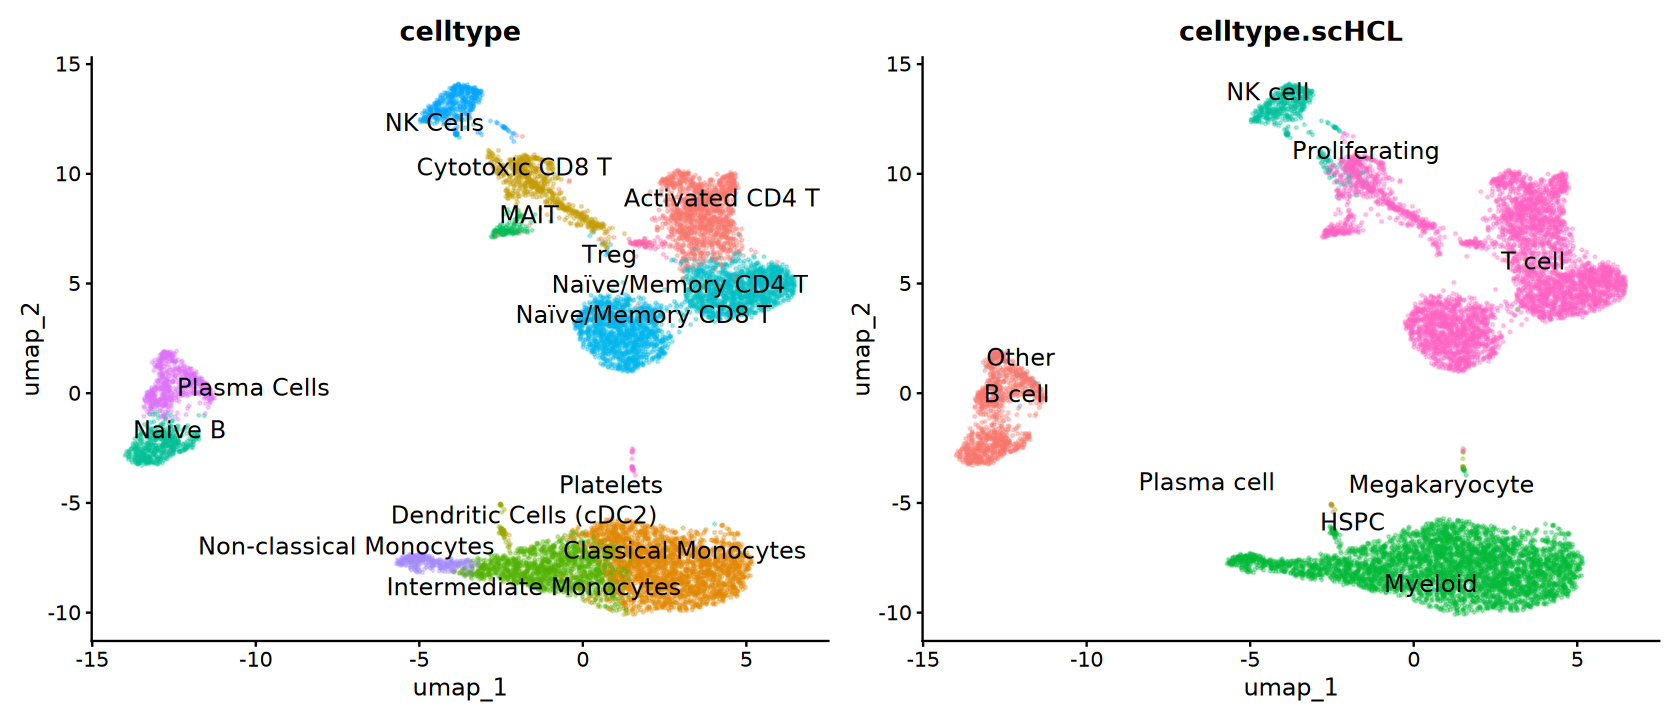

In [98]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(scrna, reduction = "umap",
        group.by = c("celltype", "celltype.scHCL"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3,  ncol = 2) &
    NoLegend()

### [CellAssign](https://github.com/Irrationone/cellassign)

### [Garnett](https://github.com/cole-trapnell-lab/garnett)

### [Azimuth](https://github.com/satijalab/azimuth)

In [ ]:
# suppressPackageStartupMessages(library(Azimuth))

In [ ]:
# # Possible network problems
# sc.temp <- RunAzimuth(
#     scrna, reference = "reference/AzimuthReference/Human_PBMC")